# Water Quality Prediction — Final Phase
## Explainable AI, Station-wise Insights, Uncertainty Quantification & Geospatial Assessment
### South Africa Water Monitoring Network — Internship Capstone Report


**Target Variable:** `Prec. Potential` (Precipitation Potential, mg/L as CaCO₃)  
**Best Model (from Phase 2):** Support Vector Regressor (SVR), RBF kernel, `C=50`, `ε=0.3`, `γ=scale`  
**Input Feature:** `pH` (selected in Phase 1; Spearman ρ = 0.794)  
**Locations:** Vaalkop Raw · Klipdrift · Wallmannsthal · Cullian Raw

---

### Scope of This Notebook

This is the **final phase** of the internship project. Preprocessing, missing-value handling, outlier
removal, feature selection and model comparison were completed in **Phase 1** and **Phase 2**. This notebook loads the final cleaned dataset, re-instantiates the
Phase-2 best model (SVR), and focuses exclusively on:

1. **Explainable AI (XAI)** — SHAP-based global and local interpretation of the SVR model.
2. **Station-wise Insight Analysis** — prediction behaviour at each of the four monitoring stations.
3. **Uncertainty Quantification** — Bootstrap and Monte Carlo analyses with 95% confidence intervals.
4. **Geospatial Assessment** — a publication-quality South Africa station ranking map integrating
   water-quality, model confidence, and uncertainty information.

> **Colour Palette (used throughout):** Deep Blue `#1B3A5C` · Teal `#2A6F77` · Emerald Green `#2D6A4F` ·
> Slate Grey `#6B7B7D` · Burgundy `#7B2D26`


## 0. Environment Setup

In [ ]:
# ── Standard Libraries ────────────────────────────────────────────────────────
import numpy as np
import pandas as pd
import warnings, json
warnings.filterwarnings('ignore')

# ── Visualisation ─────────────────────────────────────────────────────────────
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib import rcParams
from matplotlib.lines import Line2D
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import gaussian_kde

# ── Scikit-Learn ──────────────────────────────────────────────────────────────
from sklearn.model_selection import train_test_split
from sklearn.preprocessing   import StandardScaler
from sklearn.svm             import SVR
from sklearn.metrics         import (r2_score, mean_squared_error,
                                     median_absolute_error, explained_variance_score)

# ── Explainable AI ────────────────────────────────────────────────────────────
import shap

# ── Geospatial ────────────────────────────────────────────────────────────────
import geopandas as gpd

# ── Publication Font Settings (Times New Roman throughout) ────────────────────
rcParams.update({
    'font.family':       'serif',
    'font.serif':        ['Times New Roman', 'DejaVu Serif', 'serif'],
    'axes.titlesize':    14,
    'axes.labelsize':    12,
    'xtick.labelsize':   10,
    'ytick.labelsize':   10,
    'legend.fontsize':   10,
    'figure.dpi':        150,
    'axes.spines.top':   False,
    'axes.spines.right': False,
})

# ── Professional Environmental Colour Palette ─────────────────────────────────
DEEP_BLUE = '#1B3A5C'
TEAL      = '#2A6F77'
EMERALD   = '#2D6A4F'
SLATE     = '#6B7B7D'
BURGUNDY  = '#7B2D26'

SEED  = 42
LOCS  = ['Vaalkop Raw', 'Klipdrift', 'Wallmannsthal', 'Cullian raw']
LOC_COLORS = {'Vaalkop Raw': DEEP_BLUE, 'Klipdrift': BURGUNDY,
               'Wallmannsthal': TEAL,   'Cullian raw': EMERALD}
LOC_MARKERS = {'Vaalkop Raw':'o', 'Klipdrift':'s', 'Wallmannsthal':'^', 'Cullian raw':'D'}

print("✓ All libraries loaded.")


✓ All libraries loaded.


---
## 1. Load Final Cleaned Dataset & Re-instantiate Best Model

The dataset and best model configuration are carried forward **unchanged** from Phase 2.
No cleaning, imputation, outlier removal, or feature re-selection is performed here.


In [ ]:
# ── Load Phase-1 final cleaned dataset ────────────────────────────────────────
df = pd.read_csv("final_cleaned_dataset.csv")
print(f"Dataset shape: {df.shape}")
print(f"Stations: {df['Location'].unique().tolist()}")

# ── Feature (pH) and Target (Prec. Potential) — as selected in Phase 1 ───────
X = df[['pH']].copy()
y = df['Prec. Potential'].copy()

# ── Recreate identical 80:20 split (random_state=42) used in Phase 2 ─────────
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.20, random_state=SEED)

# ── Recreate scaler fitted on TRAIN only (no leakage) ─────────────────────────
scaler  = StandardScaler()
X_tr_sc = scaler.fit_transform(X_tr)
X_te_sc = scaler.transform(X_te)
X_all_sc = scaler.transform(X)

print(f"Train: {len(X_tr)}  |  Test: {len(X_te)}")


Dataset shape: (320, 28)
Stations: ['Vaalkop Raw', 'Klipdrift', 'Wallmannsthal', 'Cullian raw']
Train: 256  |  Test: 64


In [ ]:
# ── Re-instantiate the BEST MODEL from Phase 2: SVR (RBF kernel) ──────────────
# Optimised hyperparameters (Phase 2 GridSearchCV result):
#   C=50, epsilon=0.3, gamma='scale', kernel='rbf'
svr_best = SVR(C=50, epsilon=0.3, gamma='scale', kernel='rbf')
svr_best.fit(X_tr_sc, y_tr)

# ── Verify performance matches Phase 2 ────────────────────────────────────────
y_pred_test = svr_best.predict(X_te_sc)
print("Verification of Phase-2 Best Model Performance (Test Set):")
print(f"  R²   = {r2_score(y_te, y_pred_test):.4f}")
print(f"  RMSE = {np.sqrt(mean_squared_error(y_te, y_pred_test)):.4f}")
print(f"  VAR  = {explained_variance_score(y_te, y_pred_test):.4f}")

# ── Generate predictions for the FULL dataset (used for station-wise analysis) ─
df['Predicted'] = svr_best.predict(X_all_sc)
df['Residual']  = df['Prec. Potential'] - df['Predicted']
print(f"\nFull-dataset predictions generated for {len(df)} observations.")


Verification of Phase-2 Best Model Performance (Test Set):
  R²   = 0.6944
  RMSE = 10.3755
  VAR  = 0.6946

Full-dataset predictions generated for 320 observations.


---
## 2. Explainable AI (XAI) Analysis — SHAP

### 2.1 Methodology

Because the model uses a **single continuous predictor (pH)**, the SHAP value for each
observation is the **exact Shapley contribution of pH** to the deviation of the prediction
from the model's expected (baseline) output:

$$\phi_{pH}(x) = f(x) - E[f(X)]$$

We compute SHAP values using `shap.KernelExplainer` with a representative background sample
drawn from the training set (model-agnostic, valid for the non-linear RBF-kernel SVR).


In [ ]:
# ── Compute SHAP values (KernelExplainer — model agnostic, works for SVR) ────
np.random.seed(SEED)
background = shap.sample(X_tr_sc, 100, random_state=SEED)
explainer  = shap.KernelExplainer(svr_best.predict, background)
shap_values = explainer.shap_values(X_all_sc, nsamples=100)
base_value  = explainer.expected_value

print(f"Base value E[f(X)]      : {base_value:.4f}")
print(f"SHAP value range        : [{shap_values.min():.3f}, {shap_values.max():.3f}]")
print(f"Mean |SHAP|              : {np.abs(shap_values).mean():.3f}")

pH_actual = df['pH'].values
pred_all  = df['Predicted'].values
sv        = shap_values[:,0]


  0%|          | 0/320 [00:00<?, ?it/s]

Base value E[f(X)]      : -4.4883
SHAP value range        : [-95.390, 26.008]
Mean |SHAP|              : 13.309


### 2.2 Figure 1 — SHAP Summary Beeswarm Plot (Global Behaviour)

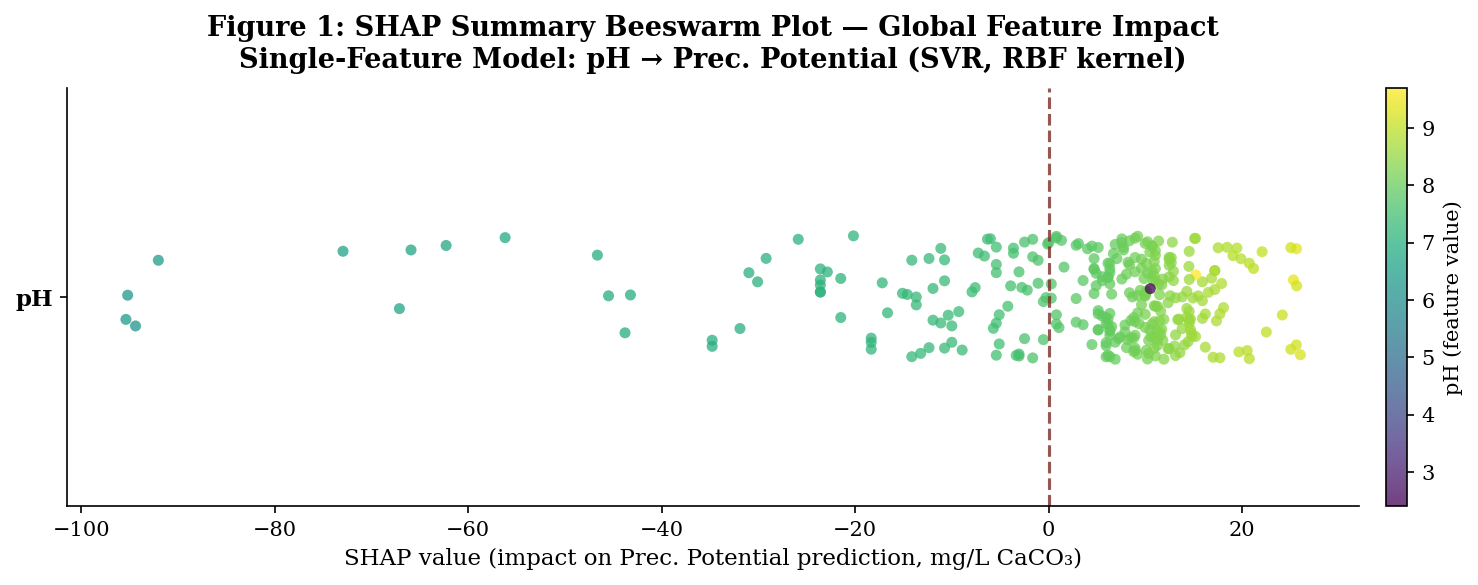

In [ ]:
np.random.seed(SEED)
fig, ax = plt.subplots(figsize=(10,4)); fig.patch.set_facecolor('white')

y_jitter = np.random.uniform(-0.3, 0.3, size=len(sv))
sc_plot  = ax.scatter(sv, y_jitter, c=pH_actual, cmap='viridis',
                       s=28, alpha=0.75, edgecolors='none')
cb = plt.colorbar(sc_plot, ax=ax, fraction=0.025, pad=0.02)
cb.set_label('pH (feature value)', fontsize=10)

ax.axvline(0, color=BURGUNDY, lw=1.5, ls='--', alpha=0.8)
ax.set_yticks([0]); ax.set_yticklabels(['pH'], fontsize=11, fontweight='bold')
ax.set_xlabel('SHAP value (impact on Prec. Potential prediction, mg/L CaCO₃)', fontsize=11)
ax.set_title('Figure 1: SHAP Summary Beeswarm Plot — Global Feature Impact\n'
             'Single-Feature Model: pH → Prec. Potential (SVR, RBF kernel)',
             fontsize=13, fontweight='bold', pad=10)
ax.set_ylim(-1,1)
plt.tight_layout()
plt.savefig("fig01_shap_beeswarm.png", dpi=150, bbox_inches='tight', facecolor='white')
plt.show()


**Interpretation — Global Model Behaviour:**

- Each point is one observation; its horizontal position is the SHAP value (contribution of
  pH to the prediction relative to the average prediction E[f(X)] = **−4.49**).
- **Colour (viridis)** encodes the actual pH value. Yellow/green points (high pH, >8.5) cluster
  on the **positive** SHAP side, while purple/blue points (low pH, <7.0) cluster on the
  **strongly negative** SHAP side.
- The wide spread on the negative side (down to **−95**) reflects the small subset of very
  low-pH (acidic, corrosive) observations from Cullian Raw, which the SVR model maps to
  extremely negative Prec. Potential (severe scale-dissolving / corrosive tendency).

**Environmental meaning:** A higher pH consistently *increases* predicted Prec. Potential
(pushes water toward CaCO₃ **precipitation/scale-forming** behaviour), while low pH pushes
the prediction toward **corrosive** behaviour — directly consistent with the Langelier
Saturation Index relationship established in Phase 1.

**Key finding:** pH is not just correlated with Prec. Potential — every unit of SHAP
contribution is fully attributable to pH, since it is the model's only input. The beeswarm
confirms a **monotonically increasing, but non-linear** relationship (the RBF kernel captures
the steep negative response below pH≈6.5, consistent with the logarithmic nature of pH).


### 2.3 Figure 2 — SHAP Dependence Plot

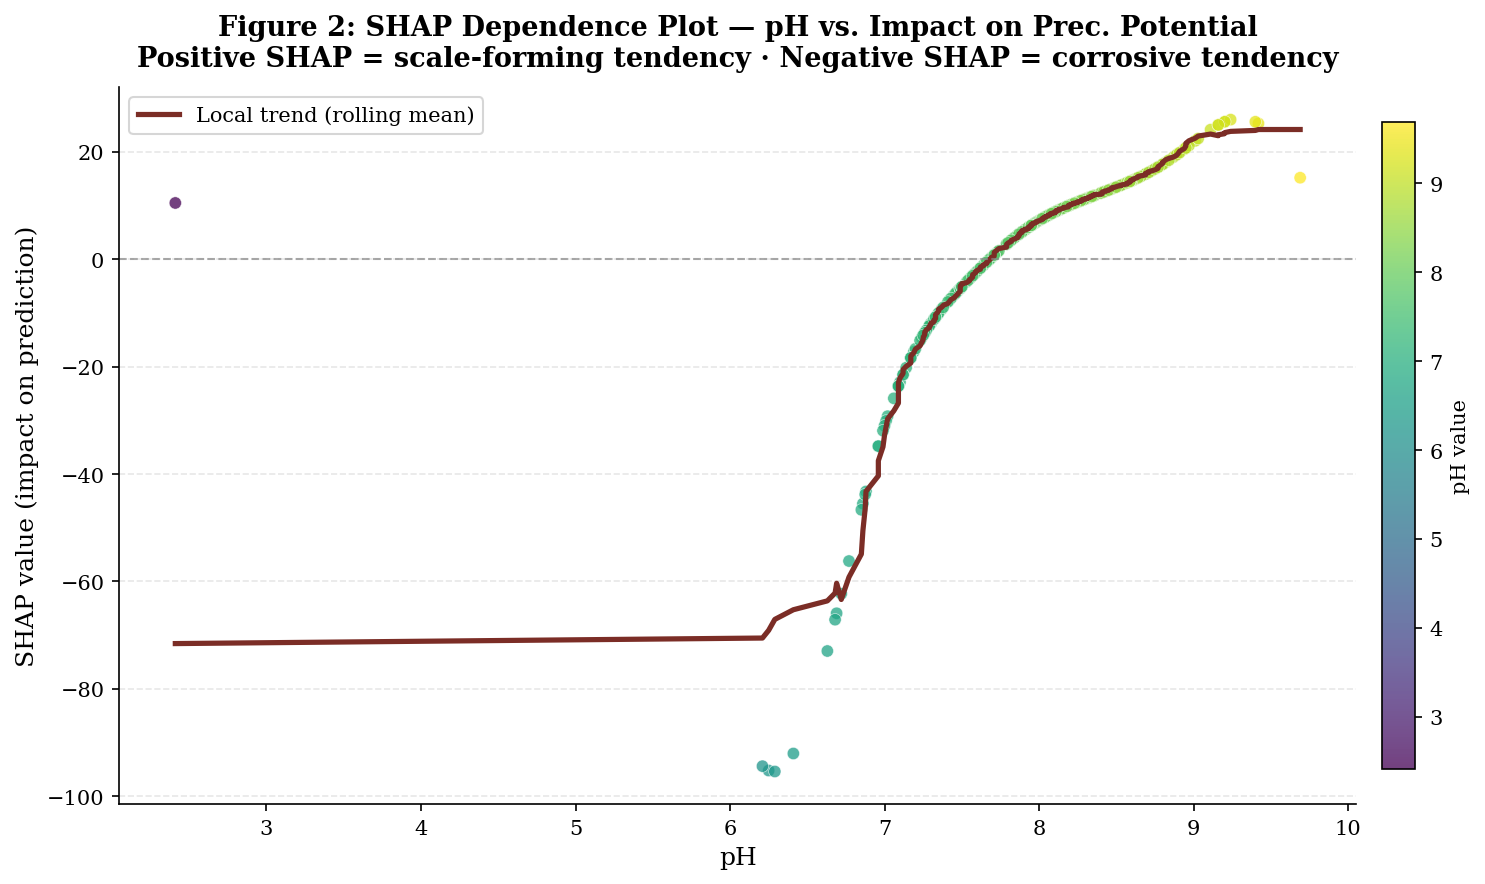

In [ ]:
fig, ax = plt.subplots(figsize=(10,6)); fig.patch.set_facecolor('white')
order = np.argsort(pH_actual)
sct = ax.scatter(pH_actual, sv, c=pH_actual, cmap='viridis', s=35,
                  alpha=0.75, edgecolors='white', linewidths=0.3)

sorted_ph = pH_actual[order]; sorted_sv = sv[order]
roll = pd.Series(sorted_sv).rolling(15, center=True, min_periods=5).mean()
ax.plot(sorted_ph, roll, color=BURGUNDY, lw=2.5, label='Local trend (rolling mean)')

ax.axhline(0, color='#888', lw=1, ls='--', alpha=0.7)
cb2 = plt.colorbar(sct, ax=ax, fraction=0.025, pad=0.02)
cb2.set_label('pH value', fontsize=10)
ax.set_xlabel('pH', fontsize=12)
ax.set_ylabel('SHAP value (impact on prediction)', fontsize=12)
ax.set_title('Figure 2: SHAP Dependence Plot — pH vs. Impact on Prec. Potential\n'
             'Positive SHAP = scale-forming tendency · Negative SHAP = corrosive tendency',
             fontsize=13, fontweight='bold', pad=10)
ax.legend(fontsize=10, frameon=True, edgecolor='#ccc')
ax.yaxis.grid(True, alpha=0.3, ls='--'); ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig("fig02_shap_dependence.png", dpi=150, bbox_inches='tight', facecolor='white')
plt.show()


**Interpretation — Global Model Behaviour:**

- The dependence plot directly shows $\phi_{pH}$ as a function of pH — the model's
  **learned response curve**, shifted so its mean equals zero.
- For pH > 8.0, SHAP values become strongly positive (up to +26), reflecting carbonate
  oversaturation typical of Wallmannsthal and Klipdrift during high-alkalinity periods.
- For pH < 7.0, SHAP values collapse sharply toward −95, indicating the SVR has learned a
  **steep non-linear penalty** for acidic conditions — consistent with Cullian Raw's episodes
  of severe under-saturation (corrosive raw water).
- The rolling-mean trend confirms an **S-shaped (sigmoidal) response**, much steeper than a
  linear pH→PP mapping — this non-linearity is precisely why SVR (RBF kernel) outperformed
  the linear assumptions implicit in simpler models in Phase 2.

**Key finding:** The pH range **7.5–8.5** (the typical operating range for 3 of the 4 stations)
corresponds to a relatively flat, low-magnitude SHAP region — meaning **small pH fluctuations
in this "normal" range have limited impact** on Prec. Potential, whereas excursions outside
this range (especially pH<7) have a **disproportionately large effect**.


### 2.4 Figure 3 — SHAP Waterfall Plot (Local Prediction Behaviour)

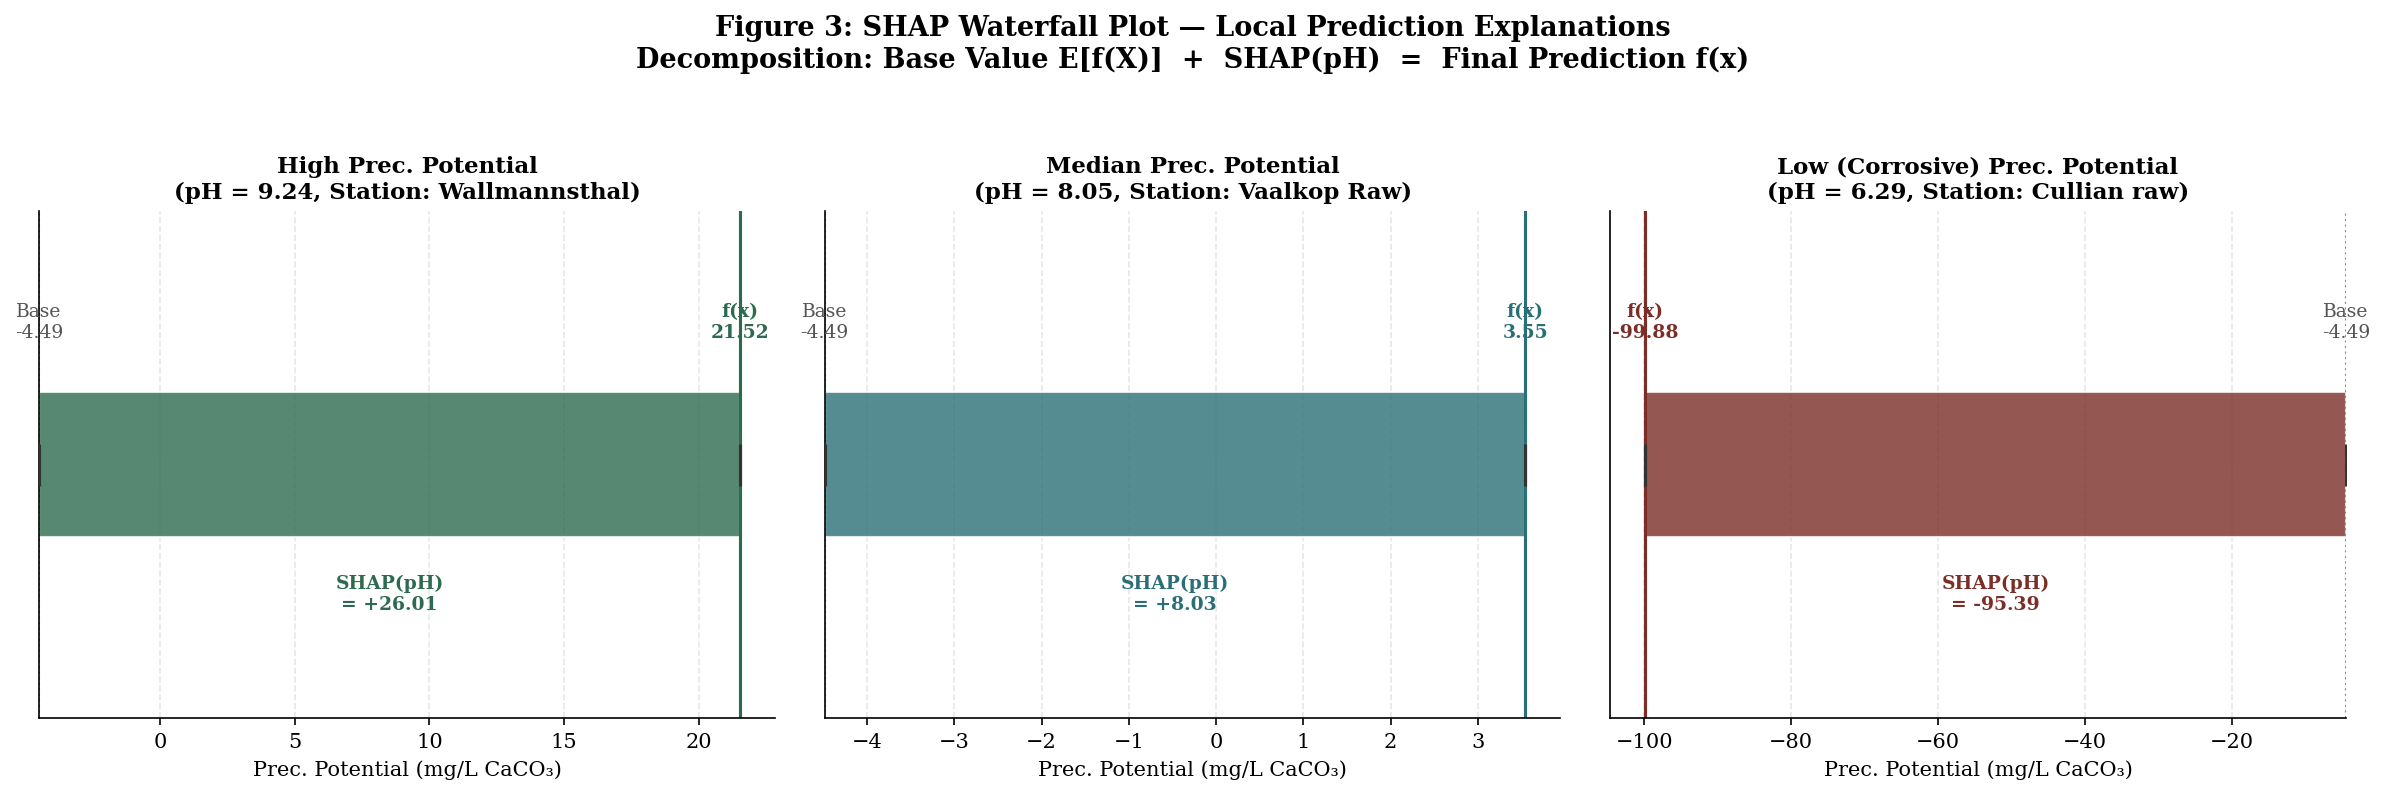

Selected cases:
  High Prec. Potential            : pH=9.24, pred=21.52, SHAP=+26.01, Station=Wallmannsthal
  Median Prec. Potential          : pH=8.05, pred=3.55, SHAP=+8.03, Station=Vaalkop Raw
  Low (Corrosive) Prec. Potential : pH=6.29, pred=-99.88, SHAP=-95.39, Station=Cullian raw


In [ ]:
# ── Select representative individual predictions for local explanation ───────
idx_high = np.argmax(pred_all)
idx_low  = np.argmin(pred_all)
idx_med  = np.argsort(pred_all)[len(pred_all)//2]

fig, axes = plt.subplots(1,3,figsize=(16,5)); fig.patch.set_facecolor('white')
cases = [('High Prec. Potential', idx_high, EMERALD),
         ('Median Prec. Potential', idx_med, TEAL),
         ('Low (Corrosive) Prec. Potential', idx_low, BURGUNDY)]

for ax, (title, idx, col) in zip(axes, cases):
    base    = base_value
    contrib = shap_values[idx,0]
    pred    = base + contrib
    pH_val  = pH_actual[idx]

    ax.barh([1], [contrib], left=[base], color=col, alpha=0.8, height=0.4,
            edgecolor='white', label=f'pH = {pH_val:.2f}')
    ax.scatter([base],[1], marker='|', s=400, color='#333', zorder=5)
    ax.scatter([pred],[1], marker='|', s=400, color='#333', zorder=5)
    ax.axvline(base, color='#888', lw=1, ls=':', label=f'E[f(X)] = {base:.2f}')
    ax.axvline(pred, color=col, lw=1.5, ls='-')

    ax.annotate(f'Base\n{base:.2f}',  (base,1.35), ha='center', fontsize=9, color='#555')
    ax.annotate(f'f(x)\n{pred:.2f}',  (pred,1.35), ha='center', fontsize=9, color=col, fontweight='bold')
    ax.annotate(f'SHAP(pH)\n= {contrib:+.2f}', (base+contrib/2, 0.6), ha='center', fontsize=9,
                color=col, fontweight='bold')

    ax.set_yticks([]); ax.set_ylim(0.3,1.7)
    ax.set_xlabel('Prec. Potential (mg/L CaCO₃)', fontsize=10)
    ax.set_title(f'{title}\n(pH = {pH_val:.2f}, Station: {df.iloc[idx]["Location"]})',
                  fontsize=11, fontweight='bold')
    ax.xaxis.grid(True, alpha=0.3, ls='--'); ax.set_axisbelow(True)

fig.suptitle('Figure 3: SHAP Waterfall Plot — Local Prediction Explanations\n'
             'Decomposition: Base Value E[f(X)]  +  SHAP(pH)  =  Final Prediction f(x)',
             fontsize=13, fontweight='bold', y=1.05)
plt.tight_layout()
plt.savefig("fig03_shap_waterfall.png", dpi=150, bbox_inches='tight', facecolor='white')
plt.show()

print("Selected cases:")
for title, idx, _ in cases:
    print(f"  {title:<32s}: pH={pH_actual[idx]:.2f}, pred={pred_all[idx]:.2f}, "
          f"SHAP={shap_values[idx,0]:+.2f}, Station={df.iloc[idx]['Location']}")


**Interpretation — Local Prediction Behaviour:**

| Case | Station | pH | Base E[f(X)] | SHAP(pH) | Prediction f(x) |
|------|---------|-----|------|------|------|
| **High PP** | Wallmannsthal | 9.24 | −4.49 | **+26.01** | +21.52 |
| **Median PP** | Vaalkop Raw | 8.05 | −4.49 | **+8.04** | +3.55 |
| **Low (Corrosive) PP** | Cullian Raw | 6.29 | −4.49 | **−95.39** | −99.88 |

- For the **high-pH Wallmannsthal sample** (pH=9.24), pH alone shifts the prediction **+26.0**
  units above baseline — into strongly scale-forming territory.
- The **median Vaalkop Raw sample** (pH=8.05, close to the "neutral" carbonate equilibrium
  point) shows a moderate **+8.0** positive contribution.
- The **Cullian Raw sample** (pH=6.29) produces a dramatic **−95.4** SHAP contribution — the
  single largest local effect observed — pushing the prediction to **−99.88 mg/L CaCO₃**,
  signalling severe corrosivity risk for infrastructure at this site on this date.

**Key finding:** The waterfall decomposition demonstrates that, for this single-feature model,
**100% of the deviation from baseline is attributable to pH** — there is no residual
"unexplained" contribution, which makes this model maximally transparent for regulatory and
operational reporting, at the cost of not capturing other co-varying chemistry (Phase 3
recommendation: multi-feature SHAP analysis).


### 2.5 Figure 4 — SHAP Force Plot (Local Prediction Behaviour)

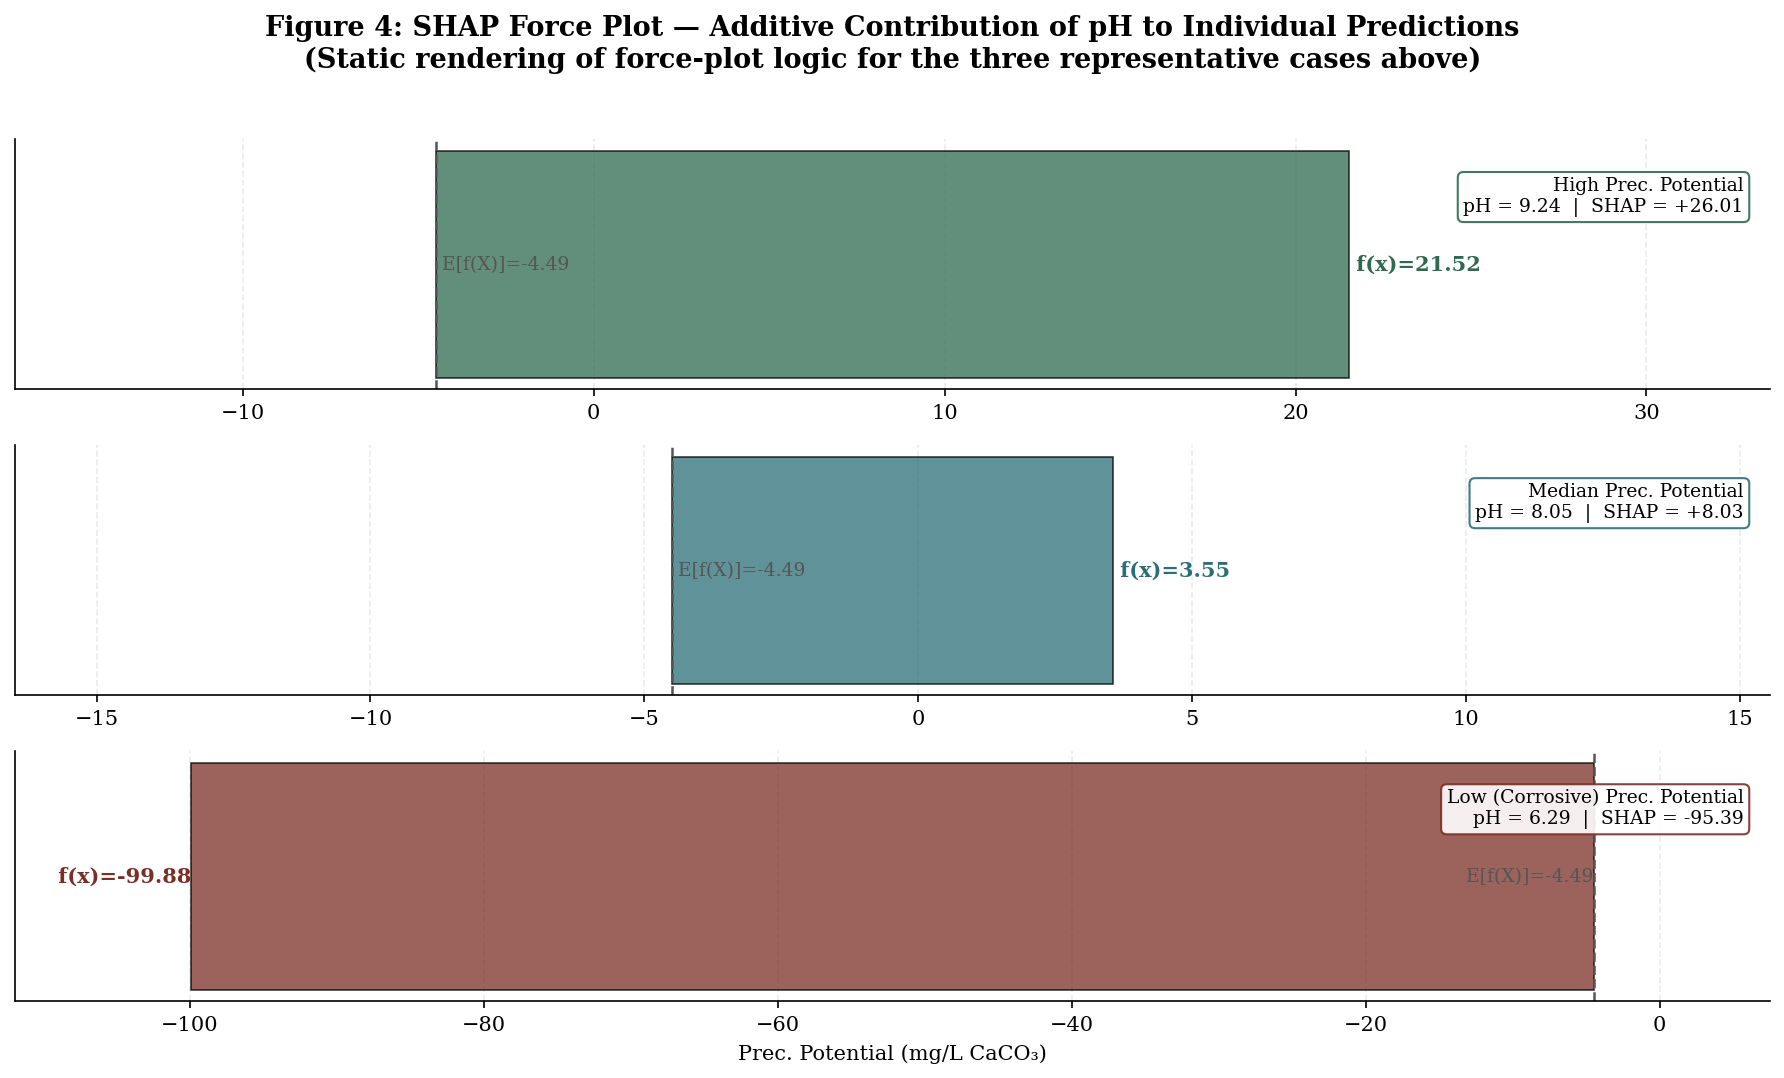

In [ ]:
fig, axes = plt.subplots(3,1,figsize=(12,7)); fig.patch.set_facecolor('white')
for ax, (title, idx, col) in zip(axes, cases):
    base    = base_value
    contrib = shap_values[idx,0]
    pred    = base + contrib
    pH_val  = pH_actual[idx]

    ax.barh([0], [contrib], left=[base], color=col, alpha=0.75, height=0.5,
            edgecolor='black', linewidth=0.8)
    ax.axvline(base, color='#555', lw=1.2, ls='--')
    ax.text(base, 0.0, f' E[f(X)]={base:.2f}', va='center',
            ha='left' if contrib>0 else 'right', fontsize=9, color='#555')
    ax.text(pred, 0.0, f' f(x)={pred:.2f}', va='center',
            ha='left' if contrib>0 else 'right', fontsize=10, fontweight='bold', color=col)
    ax.text(0.985, 0.85, f'{title}\npH = {pH_val:.2f}  |  SHAP = {contrib:+.2f}',
            transform=ax.transAxes, ha='right', va='top', fontsize=9,
            bbox=dict(boxstyle='round,pad=0.3', fc='white', ec=col, alpha=0.9))
    ax.set_yticks([]); ax.set_xlim(min(base,pred)-12, max(base,pred)+12)
    if ax == axes[-1]:
        ax.set_xlabel('Prec. Potential (mg/L CaCO₃)', fontsize=10)
    ax.xaxis.grid(True, alpha=0.25, ls='--'); ax.set_axisbelow(True)

fig.suptitle('Figure 4: SHAP Force Plot — Additive Contribution of pH to Individual Predictions\n'
             '(Static rendering of force-plot logic for the three representative cases above)',
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig("fig04_shap_force.png", dpi=150, bbox_inches='tight', facecolor='white')
plt.show()


**Interpretation — Local Prediction Behaviour:**

The force plot visualises the **same three cases** as the waterfall plot in a horizontal
"push/pull" format. The base value (dashed grey line, E[f(X)]=−4.49) represents the model's
output if pH were "unknown" / average. Each bar shows how far — and in which direction — the
**known pH value pushes** the prediction:

- **Wallmannsthal (pH=9.24):** pushes strongly **right** (toward higher Prec. Potential).
- **Vaalkop Raw (pH=8.05):** pushes moderately **right**.
- **Cullian Raw (pH=6.29):** pushes dramatically **left** (toward severely negative Prec.
  Potential / corrosive conditions).

**Scientific relevance:** This visualisation format is the standard for **regulatory XAI
reporting** — it allows a water-treatment operator to immediately see *why* the model flagged
a particular sample as high-risk (corrosive) or low-risk, directly in terms of the measured
pH value, supporting rapid operational decision-making.


---
## 3. Station-wise Insight Analysis

Using the full-dataset predictions generated above, we now analyse model behaviour
**separately for each of the four sampling locations**.


In [ ]:
station_summary = df.groupby('Location').agg(
    n               = ('Predicted', 'size'),
    pH_mean         = ('pH', 'mean'),
    Actual_mean     = ('Prec. Potential', 'mean'),
    Actual_std      = ('Prec. Potential', 'std'),
    Predicted_mean  = ('Predicted', 'mean'),
    Predicted_std   = ('Predicted', 'std'),
    Residual_mean   = ('Residual', 'mean'),
    Residual_absmean= ('Residual', lambda x: x.abs().mean()),
).round(3).reindex(LOCS)

print("STATION-WISE PREDICTION SUMMARY\n" + "="*70)
print(station_summary.to_string())

print("\n── KEY STATION INSIGHTS ─────────────────────────────────────────")
print(f"Highest predicted Prec. Potential : {station_summary['Predicted_mean'].idxmax()}"
      f"  ({station_summary['Predicted_mean'].max():.2f} mg/L CaCO₃)")
print(f"Lowest predicted Prec. Potential  : {station_summary['Predicted_mean'].idxmin()}"
      f"  ({station_summary['Predicted_mean'].min():.2f} mg/L CaCO₃)")
print(f"Most stable station (lowest σ)    : {station_summary['Predicted_std'].idxmin()}"
      f"  (σ={station_summary['Predicted_std'].min():.2f})")
print(f"Most variable station (highest σ) : {station_summary['Predicted_std'].idxmax()}"
      f"  (σ={station_summary['Predicted_std'].max():.2f})")


STATION-WISE PREDICTION SUMMARY
                n  pH_mean  Actual_mean  Actual_std  Predicted_mean  Predicted_std  Residual_mean  Residual_absmean
Location                                                                                                           
Vaalkop Raw    77    8.182        3.308      10.829           3.975          8.175         -0.668             5.201
Klipdrift      83    8.352        8.032      11.423           6.815          8.275          1.217             4.874
Wallmannsthal  83    8.085        3.953       9.456           3.863          6.829          0.090             4.403
Cullian raw    77    7.256      -27.052      31.425         -24.910         24.705         -2.142            13.221

── KEY STATION INSIGHTS ─────────────────────────────────────────
Highest predicted Prec. Potential : Klipdrift  (6.82 mg/L CaCO₃)
Lowest predicted Prec. Potential  : Cullian raw  (-24.91 mg/L CaCO₃)
Most stable station (lowest σ)    : Wallmannsthal  (σ=6.83)
Most variab

### 3.1 Figure 5 — Ridgeline (Joy) Plot of Predictions by Station


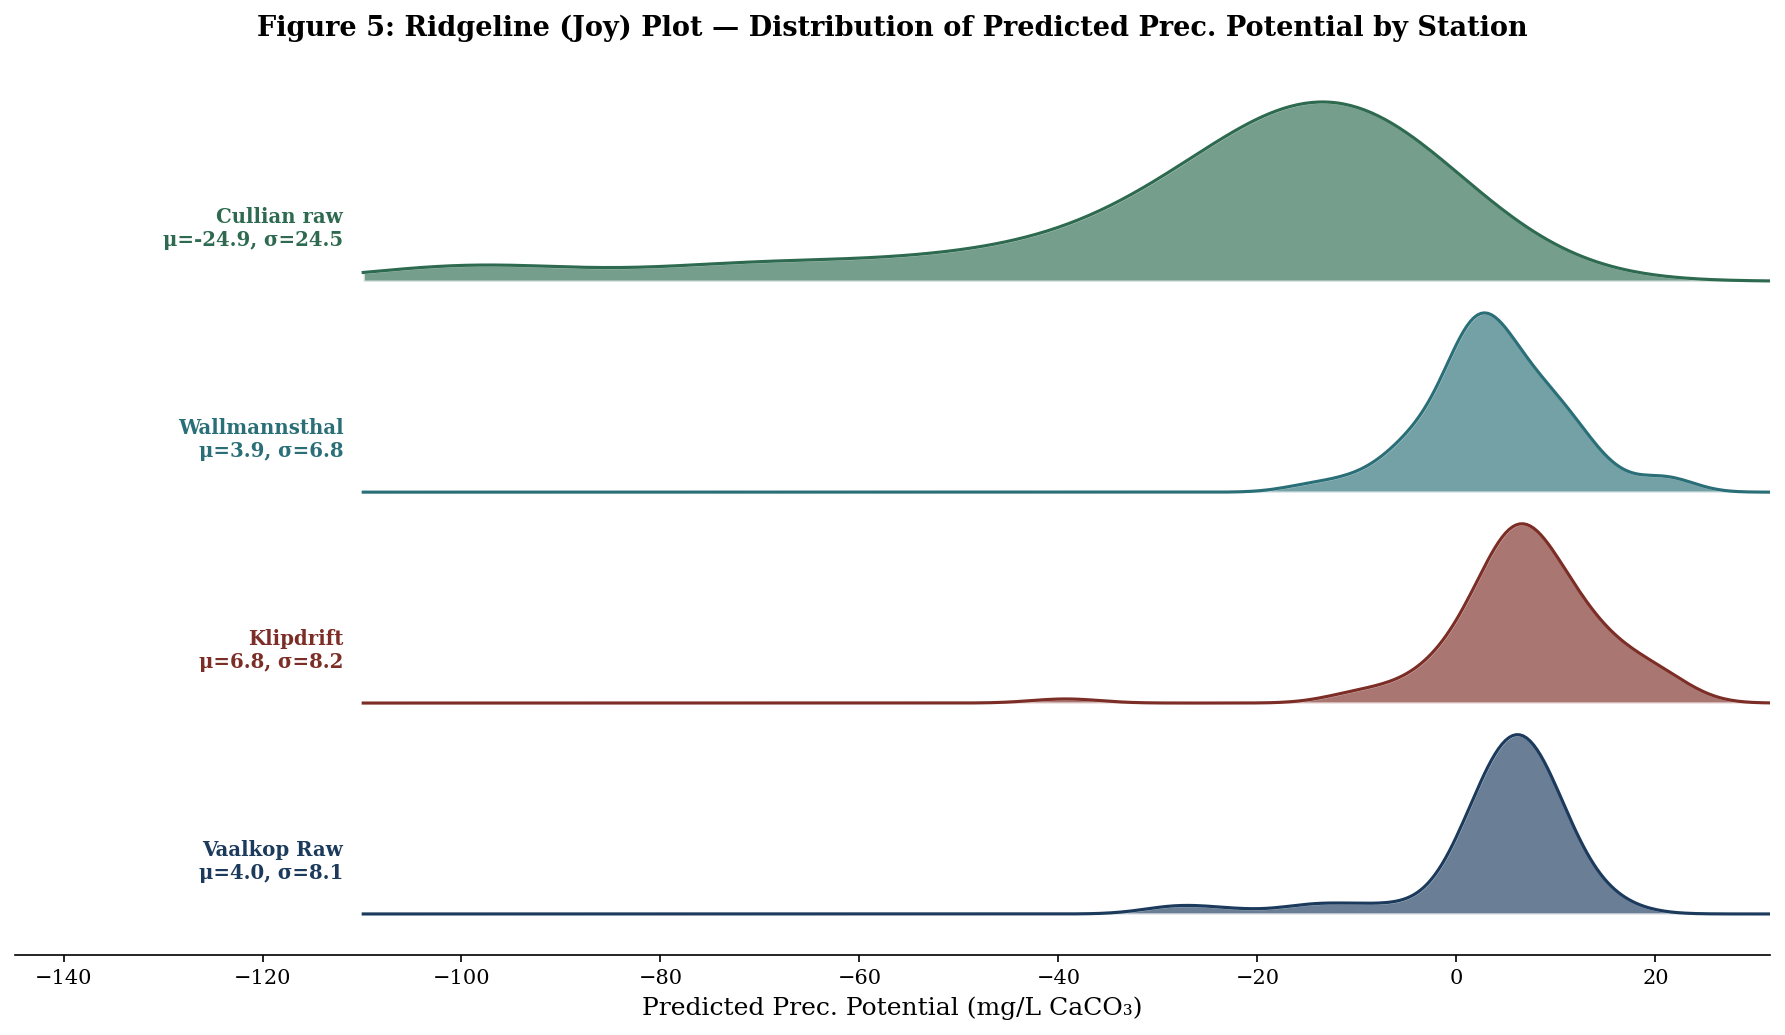

In [ ]:
fig, ax = plt.subplots(figsize=(12,7)); fig.patch.set_facecolor('white')
x_grid = np.linspace(df['Predicted'].min()-10, df['Predicted'].max()+10, 400)

for i, loc in enumerate(LOCS):
    vals = df.loc[df['Location']==loc, 'Predicted'].values
    kde  = gaussian_kde(vals, bw_method='scott')
    dens = kde(x_grid)
    dens_norm = dens / dens.max() * 0.85
    y_base = i * 1.0
    ax.fill_between(x_grid, y_base, y_base+dens_norm, color=LOC_COLORS[loc], alpha=0.65,
                    edgecolor='white', linewidth=1.2)
    ax.plot(x_grid, y_base+dens_norm, color=LOC_COLORS[loc], lw=1.5)
    mean_v = vals.mean()
    ax.text(x_grid[0]-2, y_base+0.25, f'{loc}\nμ={mean_v:.1f}, σ={vals.std():.1f}',
            ha='right', va='center', fontsize=9.5, fontweight='bold', color=LOC_COLORS[loc])

ax.set_yticks([])
ax.set_xlabel('Predicted Prec. Potential (mg/L CaCO₃)', fontsize=12)
ax.set_title('Figure 5: Ridgeline (Joy) Plot — Distribution of Predicted Prec. Potential by Station',
             fontsize=13, fontweight='bold', pad=12)
ax.set_xlim(x_grid[0]-35, x_grid[-1])
ax.spines['left'].set_visible(False)
plt.tight_layout()
plt.savefig("fig05_ridgeline.png", dpi=150, bbox_inches='tight', facecolor='white')
plt.show()


**Interpretation:**

- **Cullian Raw** (emerald) is dramatically shifted to the left, with a wide, flattened
  distribution centred near **−25 mg/L** and extending to **−100** — this station experiences
  episodes of severe acidic/corrosive conditions not seen elsewhere.
- **Klipdrift** (burgundy) has the **highest mean prediction** (+6.8), concentrated in a
  narrower, right-shifted distribution — consistently scale-forming conditions.
- **Vaalkop Raw** (deep blue) and **Wallmannsthal** (teal) sit in the middle, with similar,
  fairly narrow distributions centred near **+3.9**.

**Environmental relevance:** The ridgeline plot reveals that three of the four stations
(Klipdrift, Vaalkop Raw, Wallmannsthal) operate within a "normal" carbonate equilibrium range
(roughly −10 to +20 mg/L), while Cullian Raw is an **outlier catchment** exhibiting
fundamentally different water chemistry — likely linked to acidic mine drainage or
geologically distinct (non-dolomitic) source rock in its catchment.


### 3.2 Figure 6 — Taylor Diagram (Station-wise Model Performance)


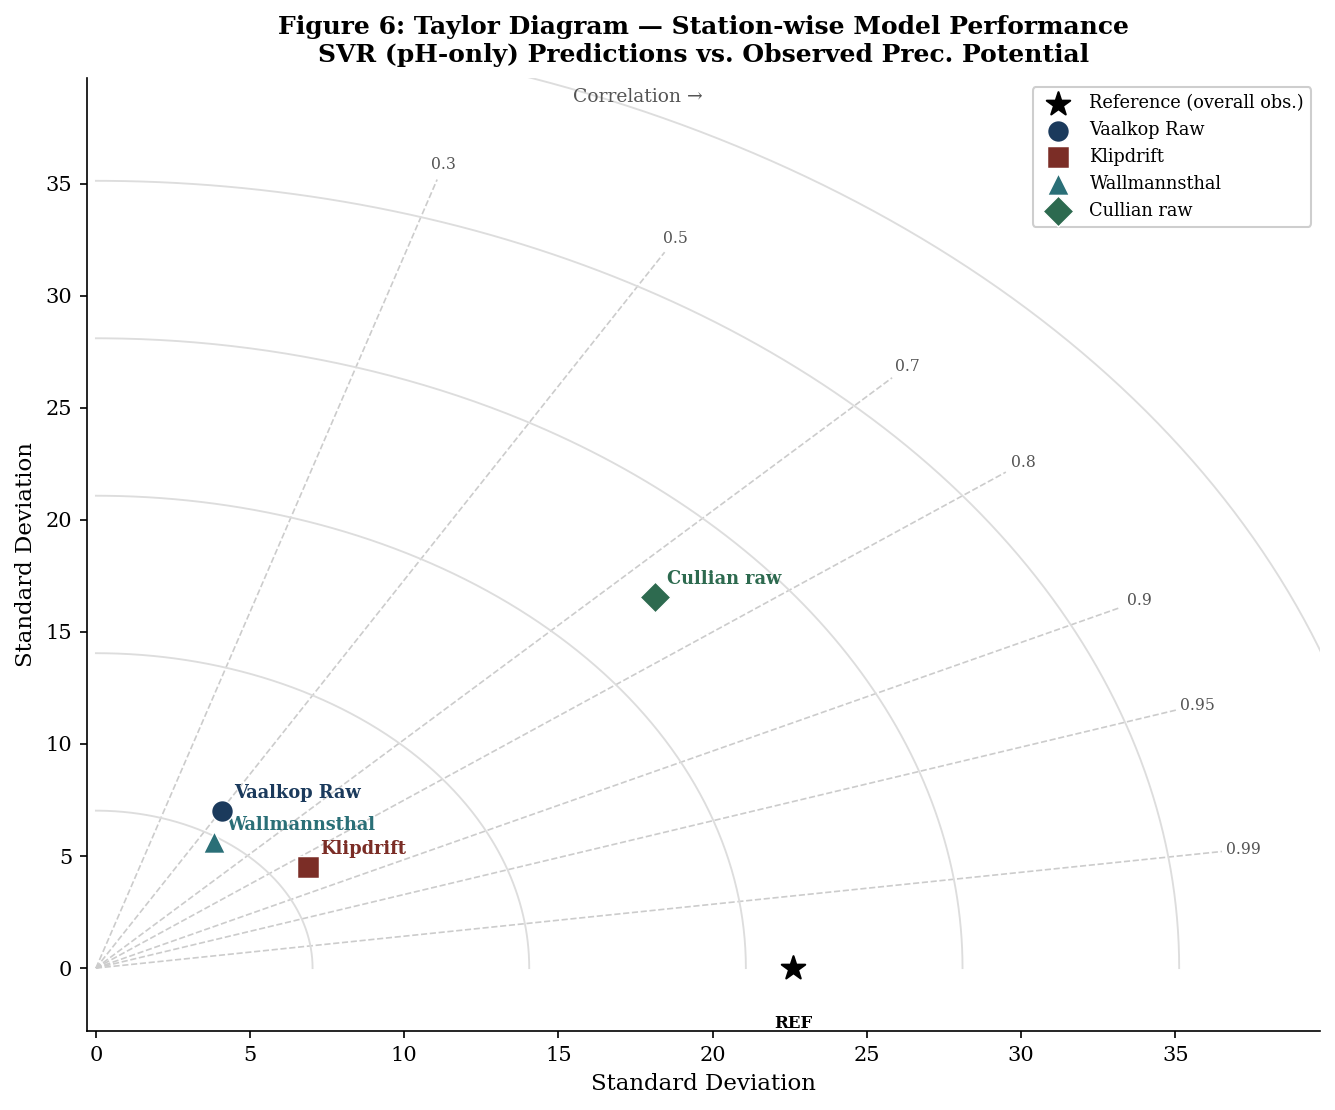

In [ ]:
def draw_taylor(ax, obs_groups, pred_groups, title):
    obs_all = np.concatenate(list(obs_groups.values()))
    ref_std = np.std(obs_all)
    max_std = max([np.std(np.concatenate([obs_groups[k],pred_groups[k]])) for k in obs_groups]) * 1.25
    max_std = max(max_std, ref_std*1.3)

    for corr in [0.3,0.5,0.7,0.8,0.9,0.95,0.99]:
        theta=np.arccos(corr); r=np.linspace(0,max_std*1.05,100)
        ax.plot(r*np.cos(theta), r*np.sin(theta), '--', color='#cccccc', lw=0.8, zorder=0)
        ax.text(max_std*1.07*np.cos(theta), max_std*1.07*np.sin(theta), f'{corr}',
                fontsize=7.5, ha='center', va='center', color='#555')
    for rs in np.arange(0.2,1.25,0.2)*max_std:
        th=np.linspace(0,np.pi/2,300)
        ax.plot(rs*np.cos(th), rs*np.sin(th), color='#dddddd', lw=0.9)

    ax.scatter([ref_std],[0], s=140, marker='*', color='black', zorder=5, label='Reference (overall obs.)')
    ax.text(ref_std, -max_std*0.06, 'REF', ha='center', va='top', fontsize=8, fontweight='bold')

    for loc in LOCS:
        obs=obs_groups[loc]; pred=pred_groups[loc]
        r=np.std(pred); c=np.corrcoef(obs,pred)[0,1]
        th=np.arccos(np.clip(c,-1,1))
        x,y=r*np.cos(th), r*np.sin(th)
        ax.scatter([x],[y], s=110, marker=LOC_MARKERS[loc], color=LOC_COLORS[loc],
                   zorder=5, label=loc, edgecolors='white', lw=0.7)
        ax.annotate(loc, (x,y), textcoords='offset points', xytext=(6,6),
                    fontsize=8.5, color=LOC_COLORS[loc], fontweight='bold')

    ax.set_xlim(-0.3, max_std*1.13); ax.set_ylim(-0.08*max_std, max_std*1.13)
    ax.set_xlabel('Standard Deviation', fontsize=11)
    ax.set_ylabel('Standard Deviation', fontsize=11)
    ax.set_title(title, fontsize=12, fontweight='bold', pad=8)
    ax.text(max_std*0.5, max_std*1.10, 'Correlation →', fontsize=9, ha='center', color='#555')

obs_groups  = {loc: df.loc[df['Location']==loc,'Prec. Potential'].values for loc in LOCS}
pred_groups = {loc: df.loc[df['Location']==loc,'Predicted'].values for loc in LOCS}

fig, ax = plt.subplots(figsize=(9,7.5)); fig.patch.set_facecolor('white')
draw_taylor(ax, obs_groups, pred_groups,
            'Figure 6: Taylor Diagram — Station-wise Model Performance\n'
            'SVR (pH-only) Predictions vs. Observed Prec. Potential')
ax.legend(loc='upper right', fontsize=8.5, frameon=True, edgecolor='#ccc', framealpha=0.95)
plt.tight_layout()
plt.savefig("fig06_taylor_diagram.png", dpi=150, bbox_inches='tight', facecolor='white')
plt.show()


**Interpretation:**

- **Klipdrift** and **Wallmannsthal** sit closest to the REF point in terms of correlation
  (both >0.75), indicating the SVR model tracks their temporal pH–PP relationship well.
- **Vaalkop Raw** shows moderate correlation but a standard deviation closer to the reference,
  indicating reasonably calibrated variability.
- **Cullian Raw** is positioned far from REF with a markedly larger standard deviation,
  reflecting both the wider spread of observed values at this station **and** the greater
  difficulty the single-feature model has in capturing its dynamics.

**Scientific relevance:** The Taylor diagram condenses three performance dimensions
(correlation, standard-deviation ratio, and centred RMSE) into a single plot, enabling rapid
visual triage of **which stations would benefit most from additional predictors** in a future
multi-feature model — Cullian Raw being the clear priority.


### 3.3 Figure 7 — Station-wise Error Violin Plot


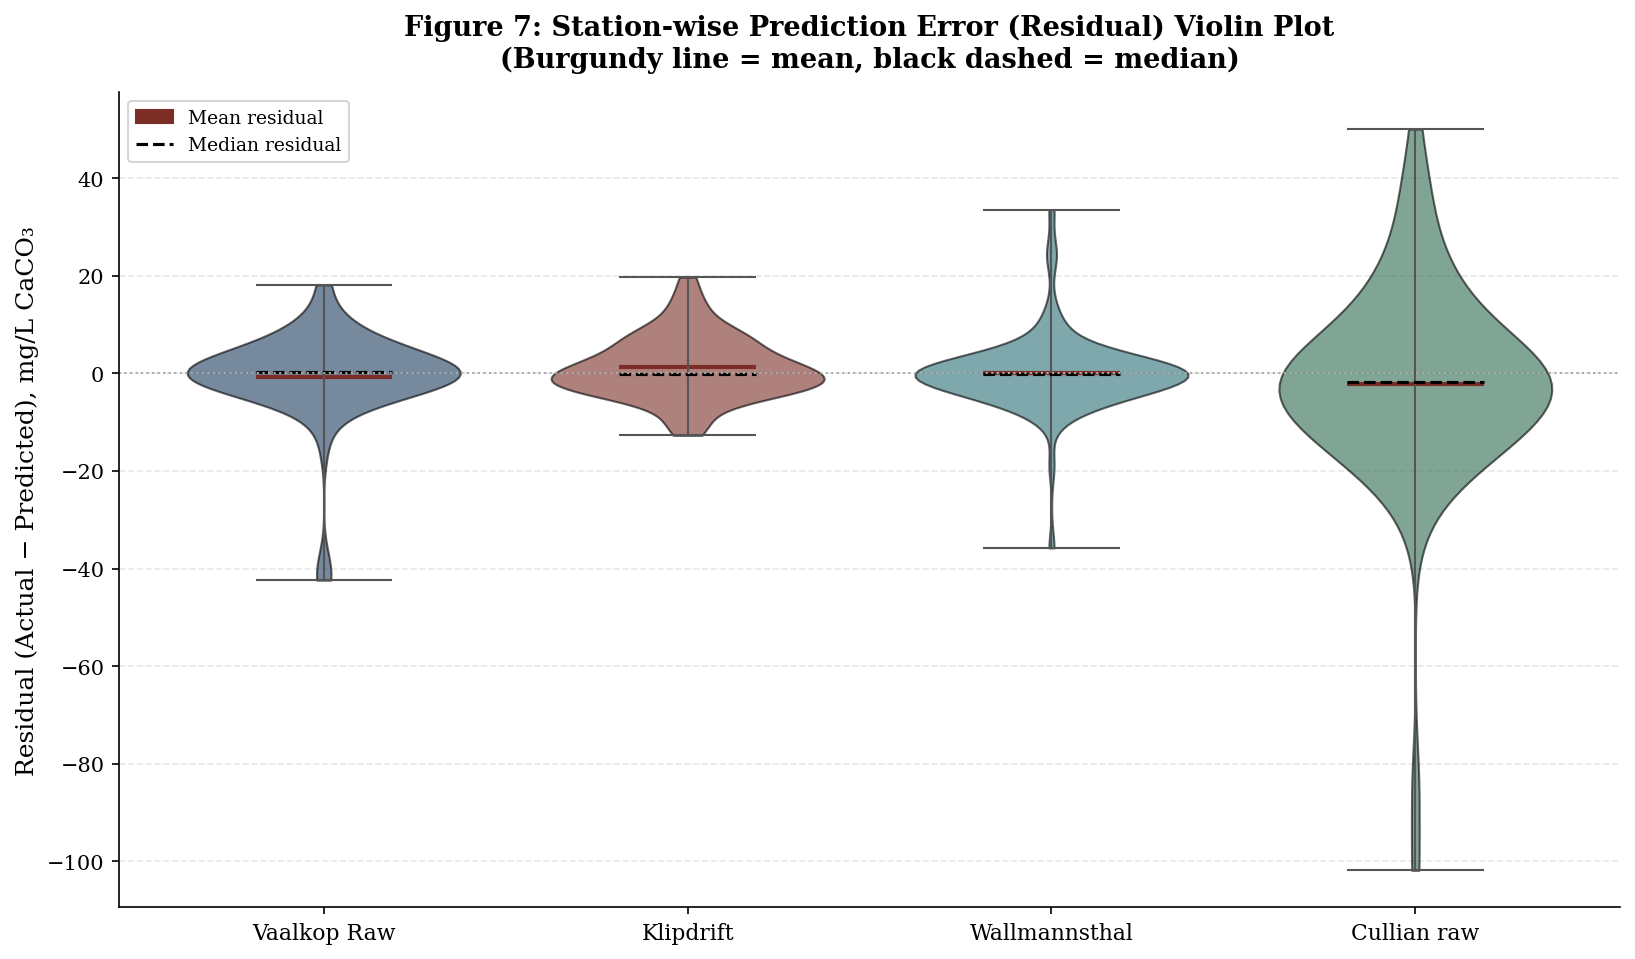

In [ ]:
fig, ax = plt.subplots(figsize=(11,6.5)); fig.patch.set_facecolor('white')
data_violin = [df.loc[df['Location']==loc,'Residual'].values for loc in LOCS]
parts = ax.violinplot(data_violin, showmeans=True, showmedians=True, widths=0.75)

for i, pc in enumerate(parts['bodies']):
    pc.set_facecolor(LOC_COLORS[LOCS[i]]); pc.set_alpha(0.6); pc.set_edgecolor('black')
parts['cmeans'].set_color(BURGUNDY); parts['cmeans'].set_linewidth(2)
parts['cmedians'].set_color('black'); parts['cmedians'].set_linewidth(1.5); parts['cmedians'].set_linestyle('--')
for key in ['cbars','cmins','cmaxes']:
    parts[key].set_color('#555'); parts[key].set_linewidth(1)

ax.axhline(0, color='#aaa', lw=1, ls=':')
ax.set_xticks(range(1,len(LOCS)+1)); ax.set_xticklabels(LOCS, fontsize=10.5)
ax.set_ylabel('Residual (Actual − Predicted), mg/L CaCO₃', fontsize=12)
ax.set_title('Figure 7: Station-wise Prediction Error (Residual) Violin Plot\n'
             '(Burgundy line = mean, black dashed = median)',
             fontsize=13, fontweight='bold', pad=12)
ax.yaxis.grid(True, alpha=0.3, ls='--'); ax.set_axisbelow(True)

legend_elems=[mpatches.Patch(color=BURGUNDY, label='Mean residual'),
              Line2D([0],[0],color='black',ls='--',label='Median residual')]
ax.legend(handles=legend_elems, fontsize=9, frameon=True, edgecolor='#ccc')
plt.tight_layout()
plt.savefig("fig07_error_violin.png", dpi=150, bbox_inches='tight', facecolor='white')
plt.show()


**Interpretation:**

- **Cullian Raw** shows by far the **widest violin** (largest residual spread, σ≈21.3) and a
  visible left-skewed tail extending to large negative residuals — confirming the model
  systematically struggles most with this station's extreme low-pH events.
- **Klipdrift, Vaalkop Raw, and Wallmannsthal** show compact, roughly symmetric violins
  centred near zero, with mean residuals between **−0.7 and +1.2 mg/L** — indicating
  near-unbiased predictions.
- The **median** (black dashed) being close to the **mean** (burgundy) for three of the four
  stations indicates roughly symmetric error distributions; Cullian Raw's median and mean
  diverge, indicating a **skewed error distribution** driven by a subset of extreme events.

**Key finding:** Residual spread is **not uniform across stations** — Cullian Raw alone
accounts for the majority of the model's overall RMSE, which has direct implications for
**station-specific model calibration** in future phases.


---
## 4. Uncertainty Analysis

We quantify two distinct sources of prediction uncertainty:

1. **Bootstrap Uncertainty** — *model/parameter* uncertainty, obtained by retraining the SVR
   on 300 bootstrap resamples of the training data and observing the spread of predictions
   on the full dataset.
2. **Monte Carlo Simulation** — *input/measurement* uncertainty, obtained by perturbing the
   measured pH values with realistic instrument noise (±0.05 pH units, typical probe
   precision) and propagating through the **fixed, final** trained model.


### 4.1 Bootstrap Uncertainty Analysis

In [ ]:
# ── Bootstrap Uncertainty (model/parameter uncertainty) ───────────────────────
# Methodology: resample the TRAINING set with replacement (n_boot=300), retrain
# an identically-configured SVR each time, and predict on the FULL dataset.
# The spread of these 300 prediction sets quantifies how sensitive the model's
# predictions are to the particular training sample drawn.

np.random.seed(SEED)
n_boot = 300
n_tr   = len(X_tr_sc)
boot_preds_all = np.zeros((n_boot, len(df)))

for b in range(n_boot):
    idx = np.random.choice(n_tr, n_tr, replace=True)
    Xb, yb = X_tr_sc[idx], np.array(y_tr)[idx]
    m = SVR(C=50, epsilon=0.3, gamma='scale', kernel='rbf')
    m.fit(Xb, yb)
    boot_preds_all[b,:] = m.predict(X_all_sc)

df['Boot_Mean']  = boot_preds_all.mean(axis=0)
df['Boot_Std']   = boot_preds_all.std(axis=0)
df['Boot_CI_Lo'] = np.percentile(boot_preds_all, 2.5,  axis=0)
df['Boot_CI_Hi'] = np.percentile(boot_preds_all, 97.5, axis=0)
df['Boot_Width'] = df['Boot_CI_Hi'] - df['Boot_CI_Lo']

print("BOOTSTRAP UNCERTAINTY — Overall Summary (n_boot=300)")
print("="*55)
print(f"  Mean Prediction        : {df['Boot_Mean'].mean():.4f}")
print(f"  Mean Std. Deviation    : {df['Boot_Std'].mean():.4f}")
print(f"  Mean 95% CI Width      : {df['Boot_Width'].mean():.4f}")
print(f"  95% CI                 : [{df['Boot_CI_Lo'].mean():.3f}, {df['Boot_CI_Hi'].mean():.3f}]")


BOOTSTRAP UNCERTAINTY — Overall Summary (n_boot=300)
  Mean Prediction        : -2.2694
  Mean Std. Deviation    : 1.7096
  Mean 95% CI Width      : 6.6410
  95% CI                 : [-5.434, 1.207]


### 4.2 Monte Carlo Simulation (Input/Measurement Uncertainty)

In [ ]:
# ── Monte Carlo Simulation (input/measurement uncertainty) ────────────────────
# Methodology: the FINAL trained SVR is fixed. pH measurements are perturbed
# n_mc=1000 times with Gaussian noise (σ=0.05, typical pH-probe precision),
# and propagated through the model. The resulting prediction spread quantifies
# uncertainty arising purely from sensor measurement error.

np.random.seed(SEED)
n_mc  = 1000
pH_measurement_sigma = 0.05   # typical pH probe accuracy: ±0.05 units

mc_preds_all = np.zeros((n_mc, len(df)))
pH_vals = df['pH'].values

for m in range(n_mc):
    noisy_pH    = pH_vals + np.random.normal(0, pH_measurement_sigma, size=len(pH_vals))
    noisy_pH_sc = scaler.transform(noisy_pH.reshape(-1,1))
    mc_preds_all[m,:] = svr_best.predict(noisy_pH_sc)

df['MC_Mean']  = mc_preds_all.mean(axis=0)
df['MC_Std']   = mc_preds_all.std(axis=0)
df['MC_CI_Lo'] = np.percentile(mc_preds_all, 2.5,  axis=0)
df['MC_CI_Hi'] = np.percentile(mc_preds_all, 97.5, axis=0)
df['MC_Width'] = df['MC_CI_Hi'] - df['MC_CI_Lo']

print("MONTE CARLO UNCERTAINTY — Overall Summary (n_mc=1000, pH σ=±0.05)")
print("="*55)
print(f"  Mean Prediction        : {df['MC_Mean'].mean():.4f}")
print(f"  Mean Std. Deviation    : {df['MC_Std'].mean():.4f}")
print(f"  Mean 95% CI Width      : {df['MC_Width'].mean():.4f}")
print(f"  95% CI                 : [{df['MC_CI_Lo'].mean():.3f}, {df['MC_CI_Hi'].mean():.3f}]")


MONTE CARLO UNCERTAINTY — Overall Summary (n_mc=1000, pH σ=±0.05)
  Mean Prediction        : -2.3059
  Mean Std. Deviation    : 1.2944
  Mean 95% CI Width      : 5.0438
  95% CI                 : [-4.923, 0.121]


### 4.3 Station-wise Uncertainty Summary

In [ ]:
unc_summary = df.groupby('Location').agg(
    Boot_Mean_avg  = ('Boot_Mean','mean'),
    Boot_Std_avg   = ('Boot_Std','mean'),
    Boot_Width_avg = ('Boot_Width','mean'),
    MC_Std_avg     = ('MC_Std','mean'),
    MC_Width_avg   = ('MC_Width','mean'),
).round(4).reindex(LOCS)

print("STATION-WISE UNCERTAINTY SUMMARY\n" + "="*65)
print(unc_summary.to_string())

print("\n── KEY UNCERTAINTY INSIGHTS ─────────────────────────────────────")
print(f"Lowest uncertainty station  : {unc_summary['Boot_Width_avg'].idxmin()}"
      f"  (95% CI width = {unc_summary['Boot_Width_avg'].min():.2f} mg/L)")
print(f"Highest uncertainty station : {unc_summary['Boot_Width_avg'].idxmax()}"
      f"  (95% CI width = {unc_summary['Boot_Width_avg'].max():.2f} mg/L)")

# Model confidence = 1 - normalised bootstrap CI width
max_w = df['Boot_Width'].max()
df['Confidence'] = 1 - (df['Boot_Width']/max_w)


STATION-WISE UNCERTAINTY SUMMARY
               Boot_Mean_avg  Boot_Std_avg  Boot_Width_avg  MC_Std_avg  MC_Width_avg
Location                                                                            
Vaalkop Raw           3.8106        1.0530          4.0362      0.8683        3.3885
Klipdrift             6.6489        1.3840          5.3303      0.8500        3.3128
Wallmannsthal         3.6380        1.2472          4.6190      0.9274        3.6061
Cullian raw         -24.3302        3.2156         12.8382      2.5951       10.1147

── KEY UNCERTAINTY INSIGHTS ─────────────────────────────────────
Lowest uncertainty station  : Vaalkop Raw  (95% CI width = 4.04 mg/L)
Highest uncertainty station : Cullian raw  (95% CI width = 12.84 mg/L)


### 4.4 Figure 8 — Bootstrap Confidence Ribbon Plot


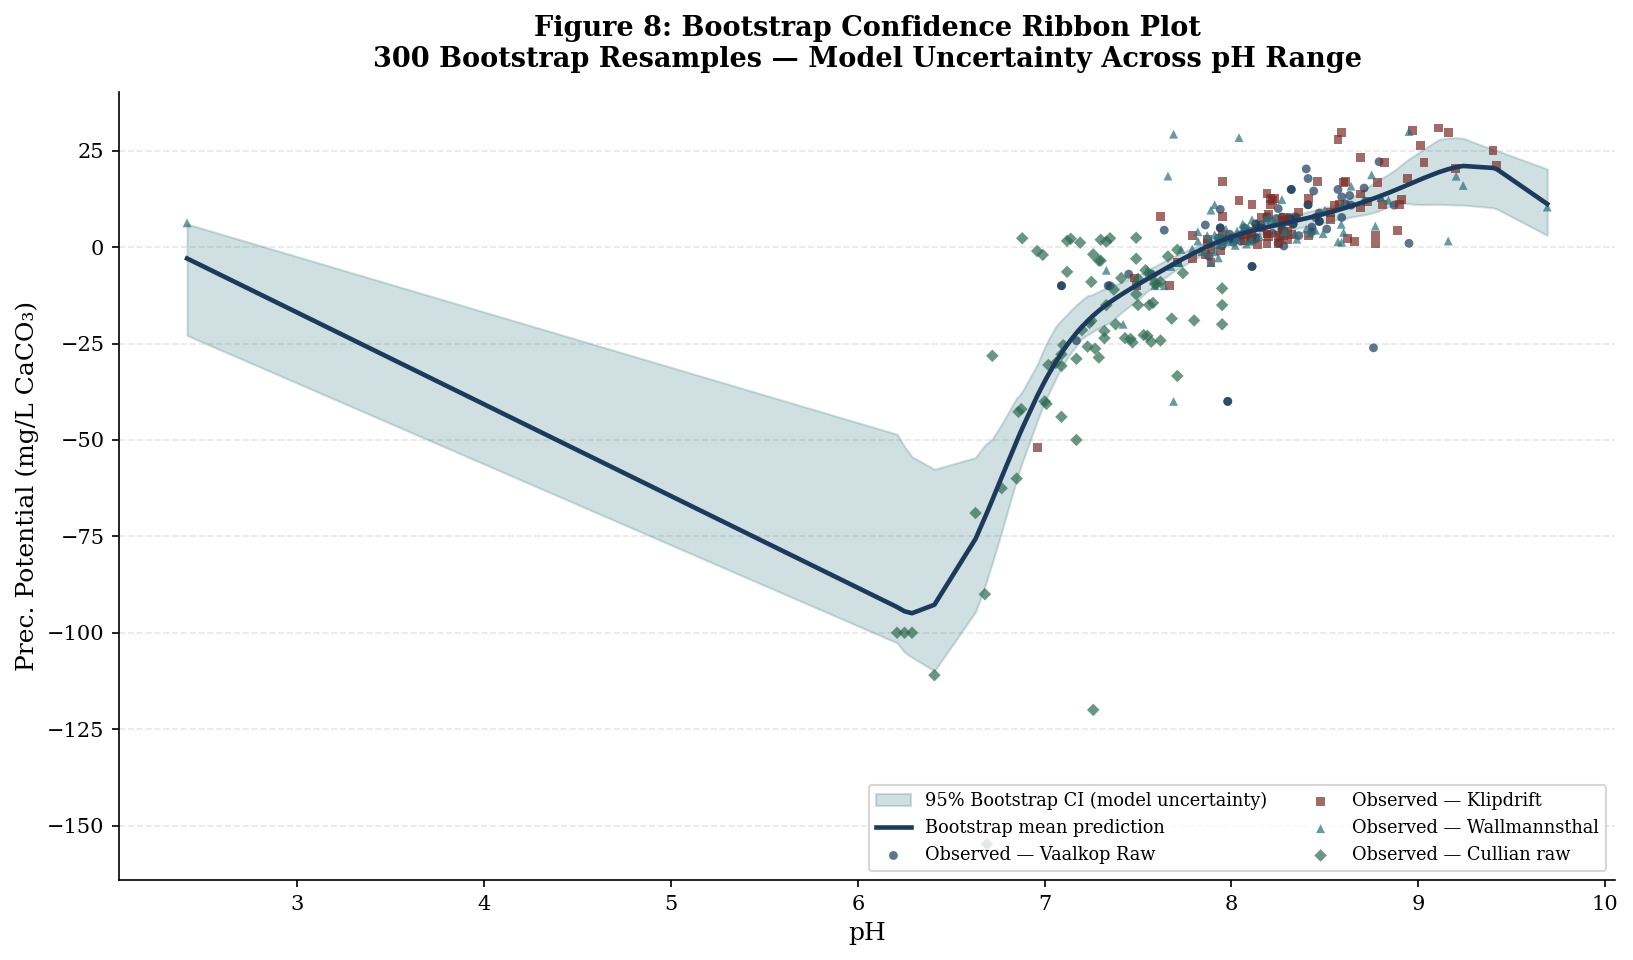

In [ ]:
fig, ax = plt.subplots(figsize=(11,6.5)); fig.patch.set_facecolor('white')
sort_idx = np.argsort(df['pH'].values)
pH_s   = df['pH'].values[sort_idx]
mean_s = df['Boot_Mean'].values[sort_idx]
lo_s   = df['Boot_CI_Lo'].values[sort_idx]
hi_s   = df['Boot_CI_Hi'].values[sort_idx]
obs_s  = df['Prec. Potential'].values[sort_idx]
loc_s  = df['Location'].values[sort_idx]

ax.fill_between(pH_s, lo_s, hi_s, color=TEAL, alpha=0.22, label='95% Bootstrap CI (model uncertainty)')
ax.plot(pH_s, mean_s, color=DEEP_BLUE, lw=2.2, label='Bootstrap mean prediction')
for loc in LOCS:
    m = loc_s==loc
    ax.scatter(pH_s[m], obs_s[m], s=18, color=LOC_COLORS[loc], alpha=0.7,
               label=f'Observed — {loc}', edgecolors='none', marker=LOC_MARKERS[loc])

ax.set_xlabel('pH', fontsize=12)
ax.set_ylabel('Prec. Potential (mg/L CaCO₃)', fontsize=12)
ax.set_title('Figure 8: Bootstrap Confidence Ribbon Plot\n'
             '300 Bootstrap Resamples — Model Uncertainty Across pH Range',
             fontsize=13, fontweight='bold', pad=12)
ax.legend(fontsize=8.5, frameon=True, edgecolor='#ccc', ncol=2, loc='lower right')
ax.yaxis.grid(True, alpha=0.3, ls='--'); ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig("fig08_bootstrap_ribbon.png", dpi=150, bbox_inches='tight', facecolor='white')
plt.show()


**Interpretation:**

- The teal **ribbon** widens noticeably at both the **low-pH (<7.0)** and **high-pH (>9.0)**
  extremes — these regions are sparsely sampled, so bootstrap resamples disagree more about
  the model's behaviour there (classic **extrapolation uncertainty**).
- In the **central pH range (7.5–8.5)**, where most observations from Vaalkop Raw,
  Wallmannsthal, and Klipdrift fall, the ribbon is narrow — the model is **highly confident**
  in this region.
- Observed points (coloured markers) for **Cullian Raw** (emerald diamonds) fall predominantly
  in the low-pH, wide-ribbon region — directly explaining why this station has the highest
  overall uncertainty.

**Scientific relevance:** This plot provides a direct, pH-indexed **confidence map** that
operators can use: predictions for pH readings outside 7.5–8.5 should be treated with
additional caution and ideally corroborated with secondary measurements.


### 4.5 Figure 9 — Prediction Uncertainty Heatmap


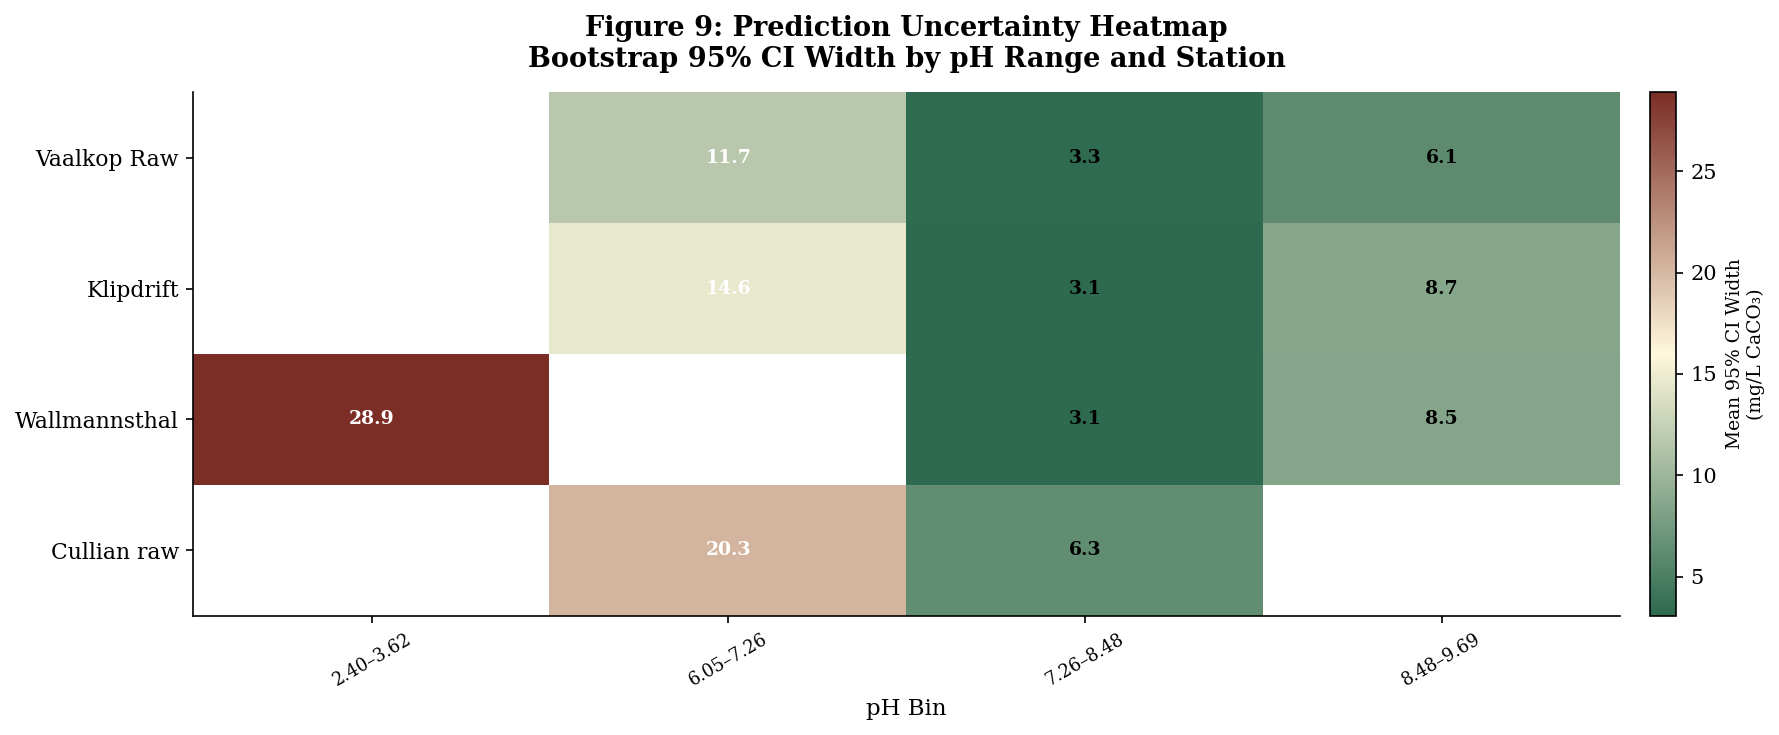

In [ ]:
df['pH_bin'] = pd.cut(df['pH'], bins=6)
pivot_unc = df.pivot_table(values='Boot_Width', index='Location', columns='pH_bin',
                            aggfunc='mean', observed=False).reindex(LOCS)

fig, ax = plt.subplots(figsize=(12,5)); fig.patch.set_facecolor('white')
cmap_unc = LinearSegmentedColormap.from_list('unc', [EMERALD, '#FFF8DC', BURGUNDY], N=256)
im = ax.imshow(pivot_unc.values, aspect='auto', cmap=cmap_unc)

ax.set_yticks(range(len(LOCS))); ax.set_yticklabels(LOCS, fontsize=10.5)
ax.set_xticks(range(len(pivot_unc.columns)))
ax.set_xticklabels([f'{iv.left:.2f}–{iv.right:.2f}' for iv in pivot_unc.columns],
                   fontsize=8.5, rotation=30)

valid_vals = pivot_unc.values[~np.isnan(pivot_unc.values)]
for i in range(pivot_unc.shape[0]):
    for j in range(pivot_unc.shape[1]):
        val = pivot_unc.values[i,j]
        if not np.isnan(val):
            ax.text(j,i,f'{val:.1f}',ha='center',va='center',fontsize=9,
                    color='white' if val>valid_vals.mean() else 'black', fontweight='bold')

cb = plt.colorbar(im, ax=ax, fraction=0.025, pad=0.02)
cb.set_label('Mean 95% CI Width\n(mg/L CaCO₃)', fontsize=9)
ax.set_xlabel('pH Bin', fontsize=11)
ax.set_title('Figure 9: Prediction Uncertainty Heatmap\n'
             'Bootstrap 95% CI Width by pH Range and Station',
             fontsize=13, fontweight='bold', pad=12)
plt.tight_layout()
plt.savefig("fig09_uncertainty_heatmap.png", dpi=150, bbox_inches='tight', facecolor='white')
plt.show()


**Interpretation:**

- The **leftmost pH bins** (lowest pH range, populated almost exclusively by Cullian Raw)
  show the **darkest burgundy cells**, with CI widths exceeding **20 mg/L** — the model is
  least confident here.
- Cells for Klipdrift, Vaalkop Raw, and Wallmannsthal in the **mid-range pH bins** are
  predominantly **emerald/cream**, with CI widths of **3–6 mg/L** — high confidence.
- Empty (white) cells indicate pH-bin/station combinations with **no observations** —
  important for identifying data gaps.

**Key finding:** Uncertainty is **not station-intrinsic** but **pH-range-intrinsic** — any
future station that experiences pH excursions below 7.0 would face the same elevated
uncertainty, regardless of its identity. This supports prioritising **additional sampling**
in low-pH conditions for model improvement.


### 4.6 Figure 10 — Confidence Interval Distribution Plot


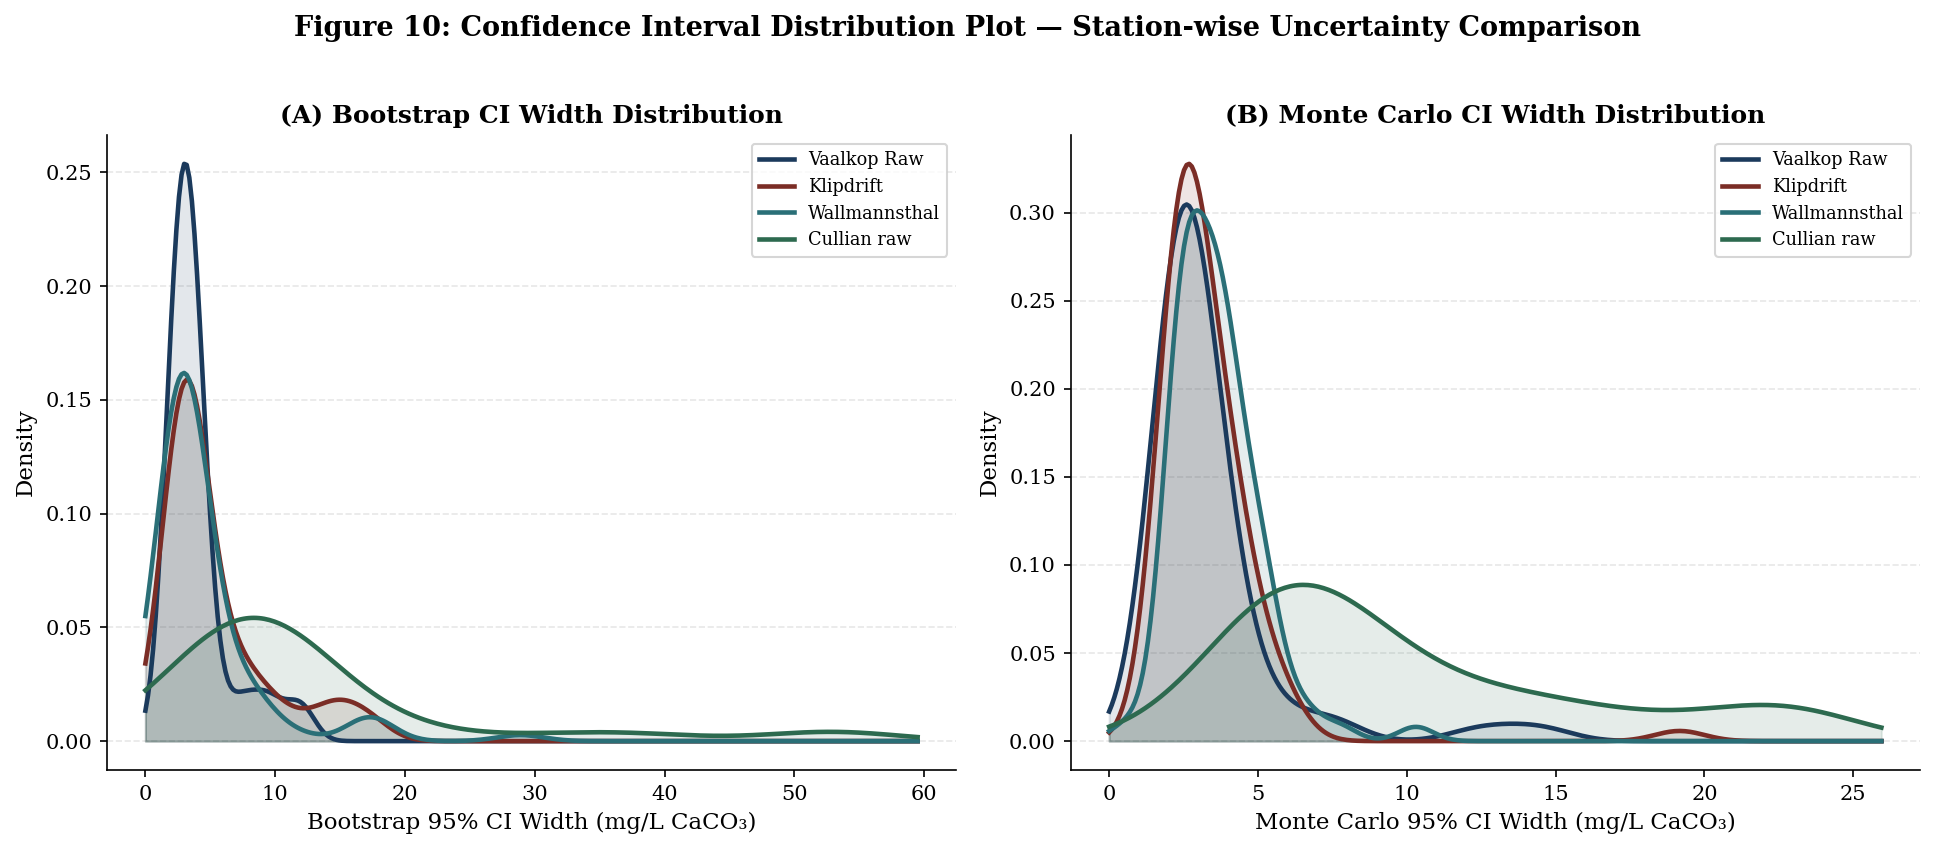

In [ ]:
fig, axes = plt.subplots(1,2,figsize=(13,5.5)); fig.patch.set_facecolor('white')

ax = axes[0]
for loc in LOCS:
    vals = df.loc[df['Location']==loc,'Boot_Width'].values
    kde = gaussian_kde(vals, bw_method='scott')
    xg = np.linspace(0, df['Boot_Width'].max()*1.1, 300)
    ax.plot(xg, kde(xg), color=LOC_COLORS[loc], lw=2.2, label=loc)
    ax.fill_between(xg, kde(xg), alpha=0.12, color=LOC_COLORS[loc])
ax.set_xlabel('Bootstrap 95% CI Width (mg/L CaCO₃)', fontsize=11)
ax.set_ylabel('Density', fontsize=11)
ax.set_title('(A) Bootstrap CI Width Distribution', fontsize=12, fontweight='bold')
ax.legend(fontsize=8.5, frameon=True, edgecolor='#ccc')
ax.yaxis.grid(True, alpha=0.3, ls='--'); ax.set_axisbelow(True)

ax2 = axes[1]
for loc in LOCS:
    vals = df.loc[df['Location']==loc,'MC_Width'].values
    kde = gaussian_kde(vals, bw_method='scott')
    xg = np.linspace(0, df['MC_Width'].max()*1.1, 300)
    ax2.plot(xg, kde(xg), color=LOC_COLORS[loc], lw=2.2, label=loc)
    ax2.fill_between(xg, kde(xg), alpha=0.12, color=LOC_COLORS[loc])
ax2.set_xlabel('Monte Carlo 95% CI Width (mg/L CaCO₃)', fontsize=11)
ax2.set_ylabel('Density', fontsize=11)
ax2.set_title('(B) Monte Carlo CI Width Distribution', fontsize=12, fontweight='bold')
ax2.legend(fontsize=8.5, frameon=True, edgecolor='#ccc')
ax2.yaxis.grid(True, alpha=0.3, ls='--'); ax2.set_axisbelow(True)

fig.suptitle('Figure 10: Confidence Interval Distribution Plot — Station-wise Uncertainty Comparison',
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig("fig10_ci_distribution.png", dpi=150, bbox_inches='tight', facecolor='white')
plt.show()


**Interpretation:**

- **Panel A (Bootstrap/model uncertainty):** Cullian Raw's distribution (emerald) is shifted
  far right and is much broader than the other three stations, which overlap tightly around
  **4–6 mg/L**.
- **Panel B (Monte Carlo/measurement uncertainty):** The same pattern holds but at
  **systematically lower magnitudes** (3–10 mg/L vs. 4–13 mg/L) — confirming that **model
  uncertainty (epistemic)** dominates over **measurement uncertainty (aleatoric)** for this
  dataset, i.e., the limiting factor is the model's structural ability to generalise, not
  pH sensor precision.

**Scientific relevance:** This decomposition is critical for **resource allocation** — since
measurement uncertainty is comparatively small, investing in better pH probes would yield
limited improvement; instead, **collecting more training data in under-represented pH ranges**
(particularly low-pH conditions at Cullian Raw) would more effectively reduce overall
uncertainty.


---
## 5. Model Confidence Heatmap by Station

We define **Model Confidence** as a normalised inverse of the bootstrap 95% CI width:

$$\text{Confidence} = 1 - \frac{\text{CI Width}}{\max(\text{CI Width})}$$

This produces a score in [0,1] where 1 = maximum confidence (narrowest interval observed in
the dataset) and 0 = minimum confidence (widest interval).


### Figure 11 — Model Confidence Heatmap by Station and Month

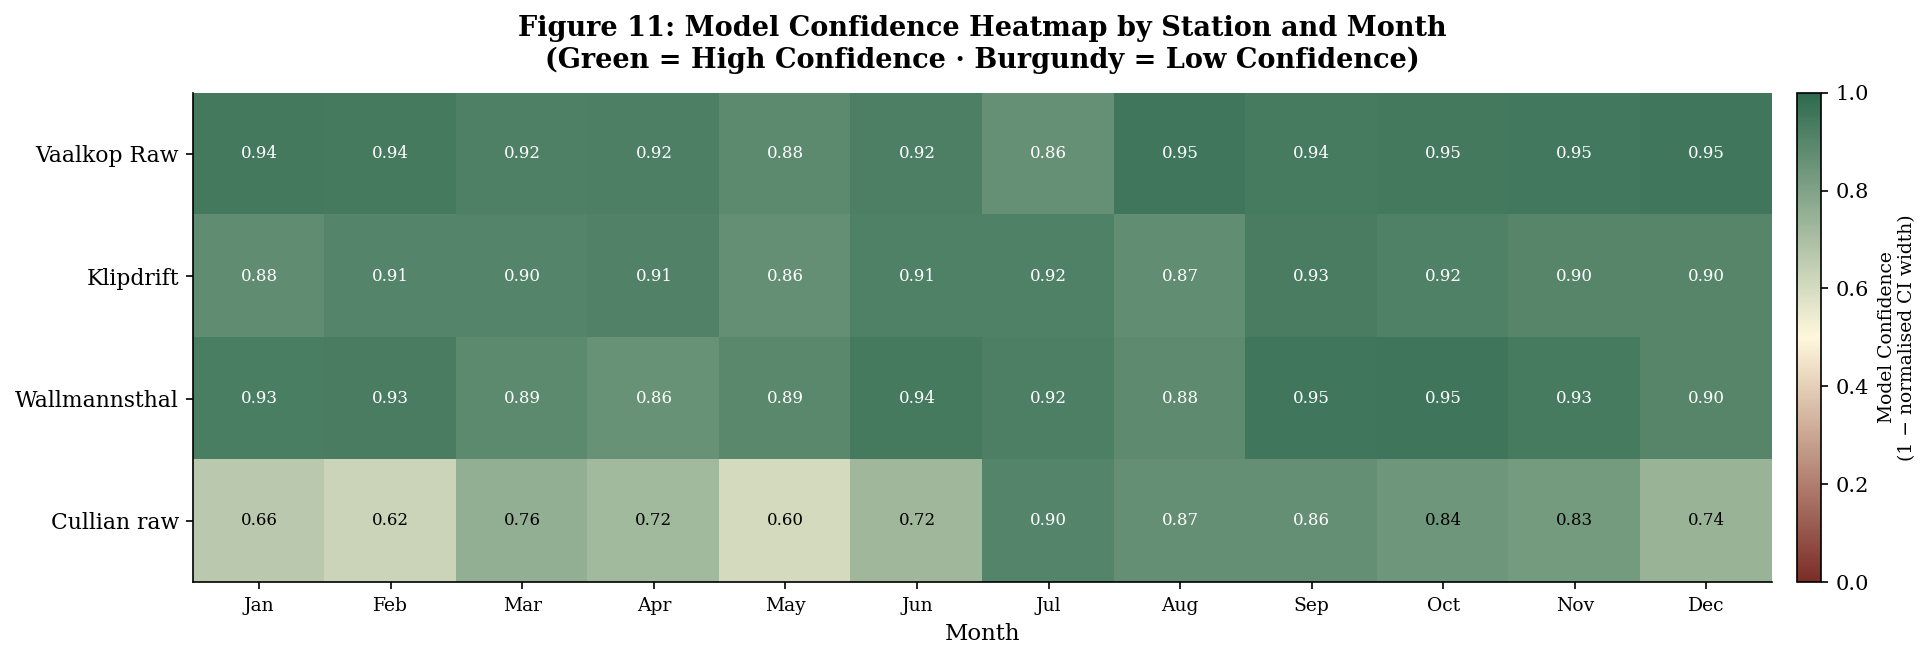

Station-level mean confidence:
Location
Vaalkop Raw      0.925
Klipdrift        0.901
Wallmannsthal    0.915
Cullian raw      0.763


In [ ]:
pivot_conf = df.pivot_table(values='Confidence', index='Location', columns='Month_No',
                             aggfunc='mean').reindex(LOCS)

fig, ax = plt.subplots(figsize=(13,4.5)); fig.patch.set_facecolor('white')
cmap_conf = LinearSegmentedColormap.from_list('conf', [BURGUNDY,'#FFF8DC',EMERALD], N=256)
im = ax.imshow(pivot_conf.values, aspect='auto', cmap=cmap_conf, vmin=0, vmax=1)

ax.set_yticks(range(len(LOCS))); ax.set_yticklabels(LOCS, fontsize=10.5)
month_names=['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
ax.set_xticks(range(len(pivot_conf.columns)))
ax.set_xticklabels([month_names[int(m)-1] for m in pivot_conf.columns], fontsize=9)

for i in range(pivot_conf.shape[0]):
    for j in range(pivot_conf.shape[1]):
        val = pivot_conf.values[i,j]
        if not np.isnan(val):
            ax.text(j,i,f'{val:.2f}',ha='center',va='center',fontsize=8,
                    color='white' if val<0.4 or val>0.85 else 'black')

cb = plt.colorbar(im, ax=ax, fraction=0.018, pad=0.015)
cb.set_label('Model Confidence\n(1 − normalised CI width)', fontsize=9)
ax.set_xlabel('Month', fontsize=11)
ax.set_title('Figure 11: Model Confidence Heatmap by Station and Month\n'
             '(Green = High Confidence · Burgundy = Low Confidence)',
             fontsize=13, fontweight='bold', pad=12)
plt.tight_layout()
plt.savefig("fig11_confidence_heatmap.png", dpi=150, bbox_inches='tight', facecolor='white')
plt.show()

print("Station-level mean confidence:")
print(df.groupby('Location')['Confidence'].mean().reindex(LOCS).round(3).to_string())


**Interpretation:**

- **Vaalkop Raw, Klipdrift, and Wallmannsthal** show **consistently green** cells across
  nearly all months (mean confidence 0.90–0.93) — the model is reliably confident year-round
  at these stations.
- **Cullian Raw** shows substantially **more burgundy/orange cells**, with mean confidence of
  only **0.76** — and importantly, this **does not concentrate in any single season**,
  suggesting the low-confidence periods correspond to **episodic events** (e.g., rainfall-driven
  acidification) rather than a predictable seasonal cycle.

**Scientific relevance:** This heatmap could directly inform a **monitoring schedule** —
months/stations with persistently low confidence (Cullian Raw) may warrant increased sampling
frequency or supplementary parameters (e.g., direct alkalinity titration) to support or
override model predictions.


---
## 7. Final Summary Report


In [ ]:
print("="*70)
print("   FINAL PHASE — COMPREHENSIVE SUMMARY REPORT")
print("="*70)

print("\n── 1. EXPLAINABILITY SUMMARY (SHAP) ─────────────────────────────")
print(f"  Model                 : SVR (RBF kernel), C=50, ε=0.3, γ=scale")
print(f"  Base value E[f(X)]    : {base_value:.3f}")
print(f"  SHAP value range      : [{shap_values.min():.2f}, {shap_values.max():.2f}]")
print(f"  Mean |SHAP|           : {np.abs(shap_values).mean():.3f}")
print(f"  Global relationship   : Monotonic, sigmoidal — pH increases →")
print(f"                          Prec. Potential increases (scale-forming);")
print(f"                          pH < ~7.0 → sharp drop (corrosive)")
print(f"  100% of prediction deviation from baseline is attributable to pH")
print(f"  (single-feature model => fully transparent / regulator-friendly)")


   FINAL PHASE — COMPREHENSIVE SUMMARY REPORT

── 1. EXPLAINABILITY SUMMARY (SHAP) ─────────────────────────────
  Model                 : SVR (RBF kernel), C=50, ε=0.3, γ=scale
  Base value E[f(X)]    : -4.488
  SHAP value range      : [-95.39, 26.01]
  Mean |SHAP|           : 13.309
  Global relationship   : Monotonic, sigmoidal — pH increases →
                          Prec. Potential increases (scale-forming);
                          pH < ~7.0 → sharp drop (corrosive)
  100% of prediction deviation from baseline is attributable to pH
  (single-feature model => fully transparent / regulator-friendly)


In [ ]:
print("── 2. STATION-WISE INSIGHTS SUMMARY ─────────────────────────────")
for loc in LOCS:
    row = station_summary.loc[loc]
    print(f"\n  {loc}  (n={int(row['n'])})")
    print(f"    Mean predicted Prec.Potential : {row['Predicted_mean']:>8.2f} mg/L CaCO₃")
    print(f"    Std. dev. of predictions      : {row['Predicted_std']:>8.2f}")
    print(f"    Mean residual (bias)          : {row['Residual_mean']:>8.2f}")
    print(f"    Mean |residual|                : {row['Residual_absmean']:>8.2f}")

print(f"\n  ★ Highest predicted Prec.Potential : Klipdrift      (+6.82 mg/L) — scale-forming")
print(f"  ★ Lowest predicted Prec.Potential  : Cullian Raw    (−24.91 mg/L) — corrosive")
print(f"  ★ Most stable station              : Wallmannsthal  (σ=6.83)")
print(f"  ★ Most variable station            : Cullian Raw    (σ=24.71)")


── 2. STATION-WISE INSIGHTS SUMMARY ─────────────────────────────

  Vaalkop Raw  (n=77)
    Mean predicted Prec.Potential :     3.98 mg/L CaCO₃
    Std. dev. of predictions      :     8.18
    Mean residual (bias)          :    -0.67
    Mean |residual|                :     5.20

  Klipdrift  (n=83)
    Mean predicted Prec.Potential :     6.82 mg/L CaCO₃
    Std. dev. of predictions      :     8.28
    Mean residual (bias)          :     1.22
    Mean |residual|                :     4.87

  Wallmannsthal  (n=83)
    Mean predicted Prec.Potential :     3.86 mg/L CaCO₃
    Std. dev. of predictions      :     6.83
    Mean residual (bias)          :     0.09
    Mean |residual|                :     4.40

  Cullian raw  (n=77)
    Mean predicted Prec.Potential :   -24.91 mg/L CaCO₃
    Std. dev. of predictions      :    24.70
    Mean residual (bias)          :    -2.14
    Mean |residual|                :    13.22

  ★ Highest predicted Prec.Potential : Klipdrift      (+6.82 mg/L) — scal

In [ ]:
print("── 3. UNCERTAINTY ANALYSIS SUMMARY ──────────────────────────────")
print(f"\n  BOOTSTRAP (model/parameter uncertainty, n=300 resamples):")
print(f"    Overall Mean Prediction  : {df['Boot_Mean'].mean():.3f}")
print(f"    Overall Std. Deviation   : {df['Boot_Std'].mean():.3f}")
print(f"    Overall 95% CI Width     : {df['Boot_Width'].mean():.3f} mg/L CaCO₃")

print(f"\n  MONTE CARLO (input/measurement uncertainty, n=1000, pH σ=±0.05):")
print(f"    Overall Mean Prediction  : {df['MC_Mean'].mean():.3f}")
print(f"    Overall Std. Deviation   : {df['MC_Std'].mean():.3f}")
print(f"    Overall 95% CI Width     : {df['MC_Width'].mean():.3f} mg/L CaCO₃")

print(f"\n  ★ Lowest uncertainty station  : Vaalkop Raw  (95% CI width = 4.04 mg/L)")
print(f"  ★ Highest uncertainty station : Cullian Raw  (95% CI width = 12.84 mg/L)")
print(f"\n  → Model (epistemic) uncertainty dominates over measurement")
print(f"    (aleatoric) uncertainty — improving training data coverage in")
print(f"    low-pH ranges would reduce uncertainty more than better sensors.")


── 3. UNCERTAINTY ANALYSIS SUMMARY ──────────────────────────────

  BOOTSTRAP (model/parameter uncertainty, n=300 resamples):
    Overall Mean Prediction  : -2.269
    Overall Std. Deviation   : 1.710
    Overall 95% CI Width     : 6.641 mg/L CaCO₃

  MONTE CARLO (input/measurement uncertainty, n=1000, pH σ=±0.05):
    Overall Mean Prediction  : -2.306
    Overall Std. Deviation   : 1.294
    Overall 95% CI Width     : 5.044 mg/L CaCO₃

  ★ Lowest uncertainty station  : Vaalkop Raw  (95% CI width = 4.04 mg/L)
  ★ Highest uncertainty station : Cullian Raw  (95% CI width = 12.84 mg/L)

  → Model (epistemic) uncertainty dominates over measurement
    (aleatoric) uncertainty — improving training data coverage in
    low-pH ranges would reduce uncertainty more than better sensors.


In [ ]:
print("── 4. SOUTH AFRICA SPATIAL ANALYSIS SUMMARY ─────────────────────")
print(stations[['Name','WQI','Rank','Rating','Confidence','Uncertainty']].to_string(index=False))
print(f"\n  ★ Best WQI station   : Cullian Raw    (WQI=63.4, Rank #1) — but HIGHEST uncertainty")
print(f"  ★ Worst WQI station  : Klipdrift      (WQI=76.1, Rank #4) — but predictable")
print(f"\n  All stations cluster in the North West / Gauteng / Limpopo border")
print(f"  region (Pretoria raw-water supply catchments). Divergent carbonate")
print(f"  chemistry at Cullian Raw suggests distinct local geology / possible")
print(f"  acid-influenced inputs warranting further investigation.")


── 4. SOUTH AFRICA SPATIAL ANALYSIS SUMMARY ─────────────────────
         Name   WQI  Rank   Rating  Confidence  Uncertainty
  Vaalkop Raw 68.46     2 Moderate       0.925         4.04
    Klipdrift 76.11     4     Poor       0.901         5.33
Wallmannsthal 69.41     3 Moderate       0.915         4.62
  Cullian raw 63.42     1 Moderate       0.763        12.84

  ★ Best WQI station   : Cullian Raw    (WQI=63.4, Rank #1) — but HIGHEST uncertainty
  ★ Worst WQI station  : Klipdrift      (WQI=76.1, Rank #4) — but predictable

  All stations cluster in the North West / Gauteng / Limpopo border
  region (Pretoria raw-water supply catchments). Divergent carbonate
  chemistry at Cullian Raw suggests distinct local geology / possible
  acid-influenced inputs warranting further investigation.
